# k-means in production

**← Continues from** [the library lab](kmeans_lab.ipynb): Labs 1–4b fit and judge a k-means model; this notebook runs it
in production. Theory: [k-means README](README.md).

Parts 1–4 are the write-up: what to store when a k-means model goes live, how to tell that the data has changed,
whether an alarm means re-clustering, and the retraining playbook. Part 5 runs all of it on a synthetic shop, with the
logic in [`kmeans_production.py`](kmeans_production.py) so it can be reused elsewhere.

| Part | What it covers |
|---|---|
| [1. Monitor](#monitor) | what to store at go-live, the held-out set, each signal's normal band, the timeline up to the alarm, signals 1–4 |
| [2. Decide](#decide) | the trigger table: which alarm leads to re-clustering, same k vs different k |
| [3. Retrain](#retrain) | the playbook, from the training window to switching models |
| [4. Profiling](#profiling) | how to describe a cluster, with the wine example |
| [5. The playbook in code](#playbook) | the module, the assumptions, and eleven scenarios from a new group to a business-fixed k; a [summary](#s-summary) at the end |


<a id="monitor"></a>

## 1. Monitor: how do we know something changed?

* Store at go-live, with the model:
  * <span style="color:red">**Before fitting k-means, hold out healthy data:**</span> set aside a random share of the
    training period's rows (e.g. 20%) and never pass them to `KMeans.fit`. 
      - The bands below are built from them. 
      - Bands built from the fitted rows come out too tight, because the centroids were fitted to those very points (fresh
    healthy data gave a far-point share of 1.2%, not training's 1.0%), so the alarms would fire too early.
      - Take random rows of the recent, representative window, not a sparse early phase.
      - Ideally ~10× the weekly batch size; with less, draw with replacement (step 1 below), since drawing without it
        from a small set makes the band too tight.
      - Keep it fixed and compare every batch against it, as NannyML and Evidently do with their reference data.
      - Re-draw it on purpose, never automatically (our procedure; the sources only require a healthy, representative
        reference), when:
        - the model is retrained: a random share of the window step 1 of [retraining](#retrain) chooses;
        - a confirmed change is accepted without a refit (e.g. a mix shift with the old model kept), or signal 3 fires
          forever;
      - Optional: add a second, sliding reference (e.g. the last month), which Evidently allows. It catches sudden jumps
        without seasonal false alarms, but on its own it would absorb a slow drift (our reasoning), so keep the fixed one
        too.
  * the monitoring baselines: each feature's training values (signal 1), the training cut-off distance (signal 4), the
    training segment shares (signal 3), and each segment's business metrics;
  * k and its evidence (elbow, silhouette, stability numbers, date, data snapshot), which step 3 compares against later;
  * <a id="normal-band"></a>the normal band of each signal (how far it wobbles by chance), built from the held-out rows
    the same way for all four; each signal below says what a draw computes, its edges, an example and the math:
    1. Draw about 4,000 batches of the weekly batch size (e.g. 1,000 points) from the held-out rows. 
      - If the held-out set is under ~10× the batch size, draw with replacement (bootstrap) so the spread stays right, or use the CLT
       formula under signals 2 and 4. 
       - Use one row per customer, in the held-out rows and in the weekly batches alike: repeat customers
       make the points correlated, so the real wobble shrinks slower than the band assumes and it comes out too tight.
    2. Score each batch with the stored model and compute the signal.
    3. Take the signal's edges across the batches; about 0.5% of healthy batches breach them by chance.
    4. Store the edges; rebuild them when the model is replaced (step 7), the held-out set is re-drawn, or the weekly
       batch size changes a lot.
    * The examples under each signal use 4 blobs, k-means fitted on 10,000 points, and 4,000 healthy batches of 1,000
      points from 100,000 points the model never saw.
    * The bands are much tighter than the rules of thumb (signal 3's edge 0.012 against "0.25 = real shift"), so with
      big batches they also flag real but tiny shifts; to skip those, also require a practical minimum (e.g. PSI > 0.1).
    * An alarm fires when a signal is outside its band in m of the last n batches (e.g. 3 of the last 5).
      * A single odd batch (a holiday week) doesn't fire it; every breach is only logged.
      * Unlike "m in a row", a drift hovering at the band's edge (out, out, in, out) still fires it.
    * <details>
      <summary><b>Why these settings, for all four signals: batch size and number of draws</b></summary>

      * Batch size decides the band's width: bigger batch, narrower honest band, but later detection.
        * Later detection: a bigger batch needs a longer window (monthly instead of weekly); a change starting early in
          the window shows only when it closes, up to a full window late.
        * How fast each band narrows with batch size is under each signal.
      * Number of draws decides the edge's precision, not its width; aim for ≥ 10 draws beyond each edge.
        * ≈ 2,000 draws for the 99.5% edge of signals 1 and 3, ≈ 4,000 for the 0.25% tails of signals 2 and 4, hence
          step 1.
        * 100 draws: 0.5 beyond the edge, wobbling ±141% of itself; edge ±0.030.
        * 500 draws: 2.5 beyond, ±63%; edge ±0.019.
        * 2,000 draws: 10 beyond, ±31%; edge ±0.011.

      </details>
* <a id="when-to-retrain"></a>**Timeline**

  ```
  t_start ─────────────── t_golive ────────────────── t_alarm_window_earliest ───── t_alarm
   training rows +         production batches:         breaches:                     retrain
   held-out rows           scored, logged, healthy     m of the last n               (step 1)
   (random, side by side)
  ```

  * `t_start`–`t_golive`: the current model's training window (training rows + held-out rows).
  * The current held-out set: random rows of [`t_start`, `t_golive`], beside the training rows in time, not after
    them; it stays in use until the retrain at `t_alarm` draws a new one.
  * `t_golive` onwards: production, every batch since go-live.
  * Breach: any batch whose signal is outside its band (above it, or below it for signals 2 and 4); every breach is
    logged.
  * `t_alarm`: the first batch, while no alarm is open, at which at least m of the last n batches are breaches; the
    alarm fires here.
    * It is always a breach itself: an in-band batch can't raise the count, so the rule can only be met on a breach.
    * So the check only needs to run at each breach: look back over the last n batches, itself included, and count
      the breaches.
    * For the triggers without a signal (k budget, upstream feature change), `t_alarm` is when the trigger arrives.
  * `t_alarm_window_earliest`: the earliest breach in the alarm window, the n batches ending at `t_alarm`.
    * It is known only in hindsight, from `t_alarm`; a breach outside the alarm window, however early, is just a
      breach.
    * Example (m = 3, n = 5), breaches at b4, b8, b11, b12: the rule is first met at b12 (b8, b11, b12 within
      b8–b12), so `t_alarm` = b12 and `t_alarm_window_earliest` = b8; b4 is just a breach.
    * A slow drift may have started earlier, inside the band, which is why step 1 tests how far back the
      training window can go instead of assuming it.
  * `t_golive` can be months or years before `t_alarm`.
  * The retrain runs at `t_alarm`: step 1 of [part 3](#retrain), with the batch at `t_alarm` as its [`test_batch`](#test-batch).
  * The alarm window is small (at most n batches) and may hold a transient, such as a holiday spike; the monitoring loop
    corrects both:
    * a new model fitted to a transient, or with bands too tight from a short window, breaches its own bands on later
      healthy weeks, so the m-of-n rule fires again and step 1 reruns on more data.
  * Two waits:
    * an upstream feature change leaves no rows under the new definition at `t_alarm`, so its retrain runs once the
      window since the change holds enough rows for the training sample and the held-out set;
    * a breach below the band of signal 2 or 4 waits until the data checks and the pipeline owner have cleared the
      inputs.
* Signal 1: drift in the input features (KS or PSI per feature).
  * *KS, two-sample Kolmogorov–Smirnov:* compares one feature's training values with today's.
    * D = the largest vertical gap between the two cumulative curves (for every value x, the share of points ≤ x): 0
      means identical, 1 means no overlap. It works on one variable at a time, hence "per feature".
    * It catches any change in the distribution, not just the mean (100,000 values on each side):

      | today vs training | D | p-value |
      |---|---|---|
      | same distribution | 0.004 | 0.41 |
      | mean shifted by 0.05 sd (negligible) | 0.022 | 5 × 10⁻²² |
      | mean shifted by 0.5 sd | 0.196 | ≈ 0 |
      | spread doubled, same mean | 0.165 | ≈ 0 |

    * Read D as the size of the shift and ignore the p-value: at 100,000 points per side any D above about 0.006 is
      "significant", which is why the negligible shift got p = 5 × 10⁻²². D has a plain meaning: D = 0.196 means
      that at some value of the feature, about 20 percentage points more of today's data sits below it.
    * D's threshold is its [band](#normal-band) (one upper edge per feature), not a fixed number like D > 0.1: with no
      change, D shrinks like 1/√n, so a fixed cut-off is too loose for big batches and too strict for small ones.
  * *PSI per feature:* cut the feature into bins (e.g. the training deciles), then PSI = Σ over bins of (today's share
    − training share) × ln(today's share ÷ training share), with an empty bin's 0 replaced by a tiny value.
  * Compute both per segment too, not only on all data: a change inside one segment gets diluted in the overall number
    (0.053 overall vs 0.203 inside the segment at std 0.5, in the example below).
  * <details>
    <summary><b>Band: what a draw computes, its edge, and why</b></summary>

    * Per draw: D between the draw's values of one feature and the stored training values.
      * One band per feature, and per feature × segment for the per-segment check.
      * PSI per feature works the same way, on the draw's bin shares.
    * Edge: the 99.5th percentile across the draws, an upper edge only.
      * A D below chance only means the batch is closer to training than sampling allows (e.g. replayed data), which a
        duplicate check catches more directly.
    * Example (batches of 1,000): median 0.027, upper edge 0.055.
    * Batch size: with no change, D shrinks like 1/√n, the reason given above for not using a fixed cut-off.
      * Median 0.050, 0.026 and 0.013 at 250, 1,000 and 4,000 points: 4× the batch halves it.

    </details>
  * <details>
    <summary><a id="signal-1-alarm"></a><b>What to do when signal 1 on all data alarms</b></summary>

    * Start the [retrain path](#retrain). It decides what changes, if anything: the centroids (step 4) or k (step 3).
      * Each feature has its own alarm, so the alarm names the features that moved: profile those first.
    * Tested on part 5's shop, each change starting in week 53:

      | change | signal 1 on all data alarms | the retrain path |
      |---|---|---|
      | every segment's basket ×1.10 | week 54 | same k, replaced silently, 0.3% of customers switch |
      | every segment's discount share +0.03 | week 54 | same k, replaced silently |
      | every segment's basket ×1.05 | week 54 | same k, kept: the refit's gain is within its noise |

    * Example: 4 round blobs (std 1), k = 4 fitted on healthy data; in a batch of 10,000 points per blob, one blob is
      replaced by two tighter sub-blobs side by side along feature x, placed so the mean squared distance to the old
      centroid stays 2.

      | sub-blob std | signal 1: KS on x, all data | KS on x, inside the segment | silhouette k = 4 / k = 5 |
      |---|---|---|---|
      | no split | 0.006 | 0.024 | 0.813 / 0.684 |
      | 0.5 | 0.053 | 0.203 | 0.811 / 0.763 |
      | 0.2 | 0.084 | 0.330 | 0.815 / **0.819** |

      * Signal 1 on all data alarms against an edge near 0.02, so the retrain path starts, and at std 0.2 the k-scan
        prefers k = 5.
      * Inside the segment D is about 4× higher, since the other three blobs dilute it on all data.
      * One constructed case: it shows the split can happen, not how often; a split along a diagonal, weaker per
        feature, is untested.

    </details>
  * <details>
    <summary><a id="segment-signal-1-alarm"></a><b>What to do when per-segment signal 1 alarms (it never decides re-clustering on its own)</b></summary>

    * Log it and [profile](#profiling) the segment: which feature moved, by how much, in original units.
    * It names a segment and a feature, and doesn't start a retrain.
    * If it persists, the segment's shape is drifting: once the change is accepted, re-draw that segment's reference
      rows, or it stays above its band every week.
    * The k + 1 test ([step 3](#retrain-step-4)) waits for the next review or for the business to ask, not for this
      alarm.
    * It runs segments × features tests, so some fire by chance every batch: use a stricter edge and require m of the
      last n batches.

    </details>
* Signal 2: WCSS per point of the training sample vs WCSS per point of the new-data. (inertia (i.e. WCSS) ÷ number of points, so
  it doesn't grow with volume, because naturally WCSS will grow since a non-negative quantity is being added to a non-negative quantity).
  * **Alarm** when it's outside its [band](#normal-band), not when it rises against training's value: fresh healthy
    data already sits higher (2.92 vs 2.86), because the centroids were fitted to the training points.
  * **Below the band:** the points sit closer to their centroids than the band allows.
    * Usually an input problem: a feature filled with a constant, clipped, or customers filtered upstream, so check
      the data first.
    * If the inputs are fine, the segments really got tighter.
  * **Why it jumps:** an average; 80% old points ≈ 2.9, 20% new-group points ≈ 33.6 (no centroid of their own) →
    ≈ 9.0, +216%.
  * **Blind spot:** a small or nearby new group moves it far less: a nearby 20% group gives +92%, against +218% for
    the far one in the example below.
  * Example: 4 round blobs, 10,000 points per batch, scored with the stored centroids.

    | batch | signal 2 |
    |---|---|
    | training period | 2.86 |
    | nothing changed | 2.92 (+2%) |
    | 20% of points form a new group | **9.08 (+218%)** |

  * <details>
    <summary><b>Band: what a draw computes, its edges, and why</b></summary>

    * Per draw: the mean squared distance of the draw's points to their nearest stored centroid, with no refit.
    * Edges: the 0.25th and 99.75th percentiles across the draws, so a batch packed unusually tight breaches too.
    * Example (batches of 1,000): lower edge 2.636, median 2.870, upper edge 3.120.
    * Batch size: the signal is an average of n distances, and an average of n independent values has spread σ / √n
      (the square-root law: Bienaymé, de Moivre).
      * So 4× the batch halves the wobble: 0.484, 0.224 and 0.107 (99.5th percentile − median) at 250, 1,000 and 4,000
        points.
      * It needs independent points, hence one row per customer.
    * CLT: the average is bell-shaped, so from a small held-out set the edges can be computed instead of drawn.
      * Edges = mean ± 2.81 × σ / √n, with σ the spread of the per-point squared distances.
      * 2.81: the 99.75% point of the bell curve.

    </details>

* Signal 3: segment shares (PSI).
  * *PSI, population stability index:* one number for how much a set of shares changed.
    * PSI = Σ over categories of (today's share − training share) × ln(today's share ÷ training share); every term is
      positive whether a share grew or shrank, so changes don't cancel. \
      **Note:** Today's share meaning incoming samples who are predicted using the currently active k-means centroids.
    * Segments are categories, so their shares fit it directly.
    * Worked example, training 25 / 25 / 25 / 25 % against today's 10 / 10 / 10 / 70 %: each shrunk segment gives
      (0.10 − 0.25) × ln(0.10 / 0.25) = 0.137, three of them 0.412; the grown one gives (0.70 − 0.25) × ln(0.70 / 0.25)
      = 0.463; PSI = 0.412 + 0.463 ≈ 0.88.
    * Rule of thumb from credit scoring: below 0.1 stable, 0.1–0.25 worth watching, above 0.25 a real shift.
      Don't alarm on it: with no change, the PSI's spread is about χ²(k − 1)/n, so its cut-off depends on the batch
      size and the number of segments (du Pisanie et al. 2023); fixed cut-offs fire too often on small batches and
      miss shifts on big ones. Use the [band](#normal-band).
    * A share of 0 makes the log undefined: replace zeros with a tiny value (e.g. 0.0001).
  * Example: 4 round blobs, 10,000 points per batch, scored with the stored centroids:

    | batch | segment shares | signal 3 (PSI) |
    |---|---|---|
    | training period | 25 / 25 / 25 / 25 % | — |
    | nothing changed | 25 / 25 / 25 / 25 % | 0.00 |
    | (incoming samples) customers shift between segments | 10 / 10 / 10 / 70 % | **0.88** |

  * <details>
    <summary><b>Band: what a draw computes, its edge, and why</b></summary>

    * Per draw: the PSI of the draw's segment shares, predicted with the stored centroids, against the stored training
      shares.
    * Edge: the 99.5th percentile across the draws, an upper edge only.
      * A PSI below chance only means the shares are closer to training than sampling allows (e.g. replayed data).
    * Example (batches of 1,000): median 0.002, upper edge 0.012.
    * Batch size: with no change, PSI ≈ χ²(k − 1) / n, so it shrinks like 1/n, faster than the other three.
      * Median 0.0096, 0.0026 and 0.0006 at 250, 1,000 and 4,000 points: 4× the batch quarters it.
      * The edge can be computed instead of drawn: χ²(k − 1)'s 99.5th percentile ÷ n, e.g. 12.84 / 1,000 ≈ 0.013 for 4
        segments, against the drawn 0.012.

    </details>
  * <details>
    <summary><a id="signal-3-alarm"></a><b>What to do when signal 3 alarms (it never decides re-clustering on its own)</b></summary>

    * Keep the model: customers moved between segments but sit near the old centroids, so the segments are still right
      and only their sizes changed; a same-k refit would move the centroids no more than refit noise.
    * Report it to the business: segment sizes drive campaign budgets and capacity.
    * Once the new mix is accepted, re-draw the held-out set and reset the training shares, or signal 3 stays above its
      band every week.

    </details>

* Signal 4: the share of new points whose distance to their predicted centroid exceeds the training cut-off (the 99th
  percentile of the training points' distances to their own centroids; 1% of training points exceed it by definition).
  * **Alarm** when it's outside its [band](#normal-band) (below 0.4% or above 2.1% at 1,000-point batches), not above
    1%: fresh healthy data already gives 1.2%.
  * **Below the band:** fewer points sit beyond the cut-off than the band allows.
    * Usually an input problem: a feature filled with a constant, clipped, or extreme customers filtered upstream, so
      check the data first.
    * If the inputs are fine, the segments really have fewer extreme members.
  * Example: 4 round blobs, 10,000 points per batch, scored with the stored centroids:

    | batch | signal 4 |
    |---|---|
    | training period | 1.0% |
    | nothing changed | 1.2% |
    | 20% of points form a new group | **20.7%** |

  * <details>
    <summary><b>Band: what a draw computes, its edges, and why</b></summary>

    * Per draw: the share of the draw's points beyond the stored training cut-off.
      * The cut-off is never recomputed per draw: a draw's own 99th percentile would put about 1% of every draw beyond
        it, whatever the data.
    * Edges: the 0.25th and 99.75th percentiles across the draws, so a batch with too few far points breaches too.
    * Example (batches of 1,000): lower edge 0.4%, median 1.1%, upper edge 2.1%.
    * Batch size: a share is an average of 0/1 values (beyond the cut-off or not), so its spread is √(p(1 − p) / n) and
      4× the batch halves the wobble.
      * 2.2, 1.0 and 0.46 percentage points (99.5th percentile − median) at 250, 1,000 and 4,000 points.
    * CLT: from a small held-out set, the upper edge can be computed as p + 2.81 × √(p(1 − p) / n), with p the held-out
      share beyond the cut-off.
      * Near 0 the share is skewed, so the bell curve misplaces the lower edge (0.2% from the formula vs 0.4% drawn);
        draw it, or use the binomial.
      * At 1,000 points the lower edge is only 4 points, so signal 4's lower edge works best on bigger batches.

    </details>

* The monitoring job and who brings what:
  * *A monitoring job, on every new batch of data (daily or weekly):*
    * validate the batch first (schema, ranges, nulls, units, constant or piled values); if it fails, fix the data
      before any of its signals count ([5.6](#s-bugs));
    * assign the batch with the stored model's `predict`, compute signals 1–4, compare each with its baseline, and log
      them to a dashboard.
    * Running the *checks* on a schedule is fine; only *retraining* waits for evidence.
  * *Who brings what:*
    * the monitoring job: signals 1–4;
    * the teams using the segments (marketing, CRM): concept drift, e.g. "coupon redemption in deal hunters fell from
      18% to 6%"; no data signal shows it;
    * the data scientist owns the thresholds, reads the alarms, and makes the call with the trigger table.
* The concept-drift case, which only people can report: business metrics per segment stop responding (run in
  [5.11](#s-concept)).
  * **Setup:** an online shop clusters customers on purchase frequency, basket size, discount usage and days since the
    last order. One segment, the "deal hunters", gets coupon campaigns, and 18% redeem them.
  * **The change:** a competitor launches free-shipping membership. The deal hunters still shop just as often and
    still use discounts, but they now chase free shipping, so coupon redemption drops to 6%.
  * **What the monitors show:**
    * the features haven't moved, so KS and PSI per feature are flat;
    * new customers sit just as close to the centroids, so the distance signal is flat;
    * the segment shares haven't moved, so their PSI is flat.
  * **What changed is the meaning.** "This segment responds to coupons" stopped being true, while the data looks the
    same. Only the business metric per segment (coupon redemption) reveals it.
  * **The fix usually isn't a plain re-fit:** you need a new feature, such as sensitivity to shipping costs, and then
    you re-cluster (step 3's first scenario continues this story).


<a id="decide"></a>

## 2. Decide: does this alarm mean re-cluster?

One row per trigger, with its threshold. **Same k:** step 4 always makes the decision; this table says what to watch
for. **Different k:** step 3 decides with the real × meaningful table, starting with the check named here. Bold rows:
the trigger leads to re-clustering.

| **trigger that fired (threshold)** | **upon refit: optimal k was same-k** | **upon refit: optimal k was different-k** |
|---|---|---|
| **signal 1 on all data**: a feature's KS D (or PSI) above its [normal band](#normal-band), for one or more features | expect step 4 to replace silently or keep: a drift shared by every segment moves the centroids together, so few customers switch segment | [profile](#profiling) the new clusters first: they should differ from the old segments in the features that alarmed |
| **signal 2**: mean squared distance above its [normal band](#normal-band) | the centroids moved; the new ones should bring the distance back into its [band](#normal-band), and if it stays high, same-k k-means can't absorb the change (step 2) | check whether the gain is real (95% rule, time windows) before anything else; often a same-k refit fixes it |
| **signal 2** below its [normal band](#normal-band): points sit closer to their centroids than the band allows; usually broken inputs, so the data checks ([5.6](#s-bugs)) and the pipeline owner come first | with clean inputs, the centroids barely move and the points sit tighter around them | the [contingency table](#contingency-table) first: the new clusters should split old segments |
| **signal 4**: far-point share above its [normal band](#normal-band) (a new group) | don't simply adopt: the silhouette can miss a faint new group, which then gets forced into an old segment; [profile](#profiling) that segment and test a larger k against the business | the [contingency table](#contingency-table) first: the new clusters should be mostly points that were far under the old model, not a split of an old segment |
| **signal 4** below its [normal band](#normal-band): fewer points sit beyond the cut-off than the band allows; usually broken inputs, so the data checks ([5.6](#s-bugs)) and the pipeline owner come first | with clean inputs, the centroids barely move and fewer customers sit far from them | the [contingency table](#contingency-table) first: the new clusters should split old segments |
| **a business metric per segment falls** (concept drift; reported by the teams) | same features, so nearly the same centroids: a refit won't help; it needs new features, which means a new model, not new centroids | meaningful first: does the new segmentation fix the business metric in the holdout? |
| **an upstream feature is added, removed, redefined or rescaled** | the old centroids no longer fit the new feature space: retraining is forced; carry names over by matching [profile cards](#profiling), not centroid distances | match old and new segments by [profile cards](#profiling), since the feature spaces differ |
| **the business changes the k budget**: how many segments it can act on (e.g. a new team or tool lets marketing run 8 distinct campaigns instead of 5; a budget cut leaves room for 3) | — (k changes by definition) | skip the k-scan (k is given); check per-cluster stability, "meaningful?" and the name mapping ([when the business fixes k](#k-budget)) |


<a id="retrain"></a>

## 3. Retrain: a playbook, run in this order once the trigger table's decision is to re-cluster

* **Step 1 · Choose the training window from the data, not by gut.**
  * *Timeline:* `t_start`, `t_golive`, `t_alarm_window_earliest` and `t_alarm` as defined [above](#when-to-retrain).
  * *Inputs, stored with the current model:*
    * the training window [`t_start`, `t_golive`];
    * the monitoring log of every batch since `t_golive` (signals 1–4 against their bands);
    * the raw rows of those batches, since the log keeps only signals and retraining needs the rows.
  * *`t_alarm_window_earliest`:* read from the log, nothing is recomputed.
  * <a id="test-batch"></a>*`test_batch`:* the latest batch, i.e. the one at `t_alarm` (later only for an upstream
    feature change); the candidate windows are compared with it.
  * *Candidate windows,* each ending just before [`test_batch`](#test-batch):

    | window | why it's there | weakness |
    |---|---|---|
    | since `t_alarm_window_earliest` | the shortest window that is surely after the change: it starts at the earliest breach in the alarm window; the right answer for an abrupt change | at most n batches (e.g. 5 weeks), so few rows; a change can start inside the band before the first breach, so it may cut off post-change rows |
    | the last 13 batches | post-change rows plus some before the first breach: the slow-drift case, where the drift was building inside the band; with weekly batches, about 3 months | 13 is a round number (a quarter of a year of weekly batches), not derived from anything |
    | the last 26 batches | the same idea for a slower drift; with weekly batches, half a year, so it also covers half a year of seasonality | same: 26 is arbitrary; if the change was abrupt, it's mostly pre-change rows |
    | everything since `t_start` | the case where the data as a whole barely changed (a transient or a small shift): the most rows, plus the healthy stretch from `t_golive` to `t_alarm_window_earliest` the current model never saw; also the natural window for the k-budget trigger, where nothing drifted | if the change is real, it mixes in everything from before it |

    * Skip a window that is the same as a longer one: with fewer than 26 batches since `t_start`, "the last 26
      batches" is everything since `t_start`, so only one of them is tried.

  * *Score, without any model:*
    * compare each candidate window's rows with [`test_batch`](#test-batch), feature by feature, with signal 1's KS test;
    * keep the longest window that matches [`test_batch`](#test-batch) on every feature;
    * the cut-off for "matches": $\color{red}{\text{[TBD]}}$
      * signal 1's edges were drawn for 1,000-row batches against the held-out set, and a window against one batch
        is a different pair of sample sizes, so it needs its own draws or a KS p-value.
  * *Triggers without drift:*
    * k budget: no breach, so the candidates are the recent windows plus everything since `t_start`;
    * upstream feature change: only data after the change uses the new feature definition, so the only candidate is
      the window since the change.
  * *Afterwards:*
    * the final fit uses the chosen window plus [`test_batch`](#test-batch), so the newest data is in the model;
    * a random share of the chosen window becomes the new model's held-out set, kept out of the fit;
    * step 2 refits the scaler on the chosen window.
  * *Features:* compute each customer's features over a rolling period (the last N days), so a customer whose
    behaviour changed is described by the new behaviour, not the old.
* <a id="k-scan"></a>**Step 2 · Fit every candidate and pick the best challenger.**
  * Refit the scaler and PCA on a sample of the chosen window; all candidates share them, and they are part of the
    model.
  * Fit each candidate with its own setting search:
    * k-means with the full k-scan: elbow, silhouette, stability and gap together;
    * a Gaussian mixture;
    * Birch;
    * HDBSCAN plus an assignment rule (e.g. a new customer joins the cluster of its nearest core point).
  * Screen each one:
    * *Labels a new customer:* `predict`, or an assignment rule.
    * *Stable:* fix each method's settings (k, `min_cluster_size`) across ~30 subsamples and compare the runs' labels
      by ARI. 
      - DBSCAN and HDBSCAN have no `predict`, so compare two runs on the points both
      subsamples contain, and report the noise share beside the ARI. 
      - Stable is necessary, not sufficient: k-means cuts the moons the same wrong way every time.
    * *Shape:* several 2-D views (not just PC1–2) and the explained-variance spectrum support it.
    * *k-means only:*
      * *Fit recovered:* the new centroids' mean squared distance is back inside its [normal band](#normal-band) (the
        range seen on past healthy weeks).
      * *Far points gone:* the share of points beyond training's 99th-percentile distance is back near 1%.
  * *Not internal scores alone:* silhouette, Calinski–Harabasz and Davies–Bouldin reward round clusters, so they
    favour k-means by construction.
  * The best challenger goes on: $\color{red}{\text{[TBD]}}$
    * if it's k-means, steps 3 and 4 split on the k its scan picked;
    * a different k or another method: the holdout (step 6) decides against the current model; the same k: step 4
      decides;
    * if it isn't k-means: $\color{red}{\text{[TBD]}}$
* <a id="retrain-step-4"></a>**Step 3 · If the scan picks a different k: is the new k real and meaningful?**
  Start with the check the trigger table (section 2) names for each trigger that fired.
  * *Real?* On about 30 subsamples (80% of the rows each, no row twice within one), fit both k on the same subsample;
    the new k must have the higher silhouette on at least 95% of them. 
    - Report the gain's median and 5th–95th percentile, e.g. +0.022 (+0.018 to +0.026). 
    - It should also win in most recent time windows (each of the last 4–6 weeks scanned separately); without timestamps skip this, and another split (country, channel) can play the same
    role. 
    - Finally, the old-vs-new contingency table should show a clean split or merge, not a reorganisation (below).
  * *Meaningful?* The new clusters' profiles differ ([profiling recipe](#profiling) below), their business outcomes
    differ, and the holdout in step 6 beats the old segmentation.

  | real? | meaningful? | decision |
  |---|---|---|
  | yes | yes | adopt the new k; map names, splitting the old name where a segment split |
  | yes | no | keep the old k for actions; track the new structure as sub-segments; if the new k is smaller because a segment emptied, adopt it and retire that segment |
  | no | — | false alarm: keep the old k |

  * *Why follow the table:*
    * Better clustering metrics alone can't justify a change: with big data even a tiny gain wins on every subsample,
      and the silhouette can miss a real change entirely.
    * The old k isn't sacred either: the data really can change.
    * Switching costs something (dashboards, campaign rules, people's vocabulary), so it needs evidence on both
      hurdles.
    * It turns "why did you change the segments?" into an answer stakeholders can check.
  * *Scenarios (online shop):*
    * **Yes, yes:** the sequel to the concept-drift case in section 1. After a shipping-sensitivity feature is added,
      the re-cluster splits the "deal hunters" into coupon responders and shipping-sensitive buyers. k = 6 beats
      k = 5 on 100% of subsamples, holds for 6 weeks, and is a clean split of one segment; in a holdout,
      free-shipping offers to the new segment lift conversion from 4% to 7%. Adopt k = 6, naming the halves "deal
      hunters: coupons" and "deal hunters: shipping".
    * **Yes, no:** a new "sessions on mobile" feature splits the "regulars" into app and web users, stable and
      persistent, but both halves have the same basket, campaign response and churn. Keep k = 5 for actions; track
      app vs web as sub-segments.
    * **No:** in Black Friday week a flood of one-off bargain shoppers forms a temporary cluster, and a 6th cluster
      wins that week's scan; two weeks later it is gone. False alarm: keep k = 5.
  * <a id="contingency-table"></a>*Reading the old-vs-new contingency table* (rows: old segments, columns: new clusters, cells: customers in both):
    * Example: old k = 3 vs new k = 4, the same 300 customers labelled by both models.

      | | new 0 | new 1 | new 2 | new 3 |
      |---|---|---|---|---|
      | **old A** | 100 | 0 | 0 | 0 |
      | **old B** | 0 | 52 | 48 | 0 |
      | **old C** | 0 | 0 | 0 | 100 |

      * Old B split into new 1 and new 2, and every new cluster draws its members from one old segment: a clean split.
      * Had old B's customers landed across new 0, 1 and 2 alongside other segments' customers, it would be a
        reorganisation.
    * Clean split: each new cluster draws almost all its members from one old segment.
    * Clean merge: each old segment goes almost entirely into one new cluster.
    * Reorganisation: members spread across several old segments.
    * Don't judge by ARI when k differs: a k change forces disagreement, so a tidy refinement can score as low as a
      messy reshuffle (10,000 customers in 4 segments of 2,500):

    | old k → new k | what happened | ARI |
    |---|---|---|
    | 4 → 5 | one segment split cleanly in half | 0.913 |
    | 4 → 8 | every segment split cleanly in half | 0.600 |
    | 4 → 3 | two segments merged cleanly | 0.714 |
    | 4 → 4 | 3.8% of customers switched segment | 0.902 |
    | 4 → 4 | 15% of customers switched segment | 0.641 |

* **Step 4 · If the scan picks the same k: keep, replace silently, or replace visibly.**
  * Definitions, all on recent data after matching each new centroid to its nearest old one:
    * *shift:* distance between a matched old and new centroid;
    * *noise:* how far that centroid moves across refits on subsamples of the recent data;
    * *fit gain:* (old centroids' mean squared distance ÷ new centroids' mean squared distance) − 1, on held-out
      recent data;
    * *fit noise:* how much the fit gain varies across those refits;
    * *switch share:* the share of recent customers whose segment changes.
  * Decide in this order:
    * Refits disagree among themselves (low ARI between them): don't replace; investigate the instability.
    * No centroid's shift exceeds its noise: keep the old model.
    * Fit gain within the fit noise: keep the old model.
    * Switch share ≈ 0: replace silently, under the same names.
    * Switch share > 0: replace visibly; [re-profile](#profiling) the moved segments, tell the teams, watch the business
      metrics.
  * Cluster spread is not a decision input; use it only to explain size to stakeholders ("the centroid moved 1.3×
    its own radius"). With the same k, report the switch share rather than the ARI: same information, easier to
    explain.
* <a id="k-budget"></a>**Step 5 · When the business fixes k (5 → 8 or 8 → 5).**

  | | 5 → 8 (more segments) | 8 → 5 (fewer segments) |
  |---|---|---|
  | statistical risk | unstable splits of noise | low |
  | business risk | paying for campaigns with no extra lift | erasing a profitable distinction |
  | what the DS brings | which splits are real, and what each extra segment is worth | a merge plan with each merge's cost |
  | evidence | per-cluster stability on subsamples; [profiles](#profiling); holdout lift of the new campaigns vs the old ones | outcome similarity per pair of segments (response, value, churn); fit lost per merge; contingency table showing a clean merge, not a reorganisation; holdout of a merged campaign vs the separate ones |
  | ways to use the capacity | sub-split only the segments whose halves really differ (two levels); spend extra campaigns on in-segment A/B tests; add features that might reveal real distinctions | merge by outcome similarity, not centroid closeness; keep a valuable distinction inside a merged segment through cheaper means (different message or offer rules, not a separate campaign); move the least valuable segment to a default "no campaign" group instead of merging it |
  | if the business still insists | deliver 8, flag the segments that aren't distinct, and let outcomes per segment decide at the next review | do their merge, state its price, and keep the old 8 labels as tags inside the merged segments so the loss is measured and the merge can be undone |

* **Step 6 · Validate before switching to a different k or another method.**
  * The fit on held-out recent data, never on the data the model was trained on.
  * A holdout experiment on live customers: randomly split the customers active during the test period into
    control (actions from the old segments) and treatment (actions from the new ones), and measure the business
    metric afterwards. Historical points can't be used: the outcomes have to follow the actions.
* **Step 7 · Switch carefully.**
  * Carry names over. 
    - Labels are arbitrary per fit (two fits of the same data swapped labels 0 and 2), so without
    this, campaign rules, dashboards and CRM tags would silently point at different customers. 
    - Match each new centroid to its nearest old one, or match [profile cards](#profiling) if the 
    feature space changed; only new or split segments get new names.
  * [Re-profile](#profiling) the segments.
  * Version the old model and keep a rollback.
  * Tell the teams whose rules use the segments.
  * Reset the monitoring baselines ([distance band](#normal-band), 99th-percentile distance, segment shares for PSI), or
    the alarms keep firing or stay silent.


<a id="profiling"></a>

## 4. Reference: profiling a cluster

Used in steps 3, 4, 5 and 7. For each cluster:

1. *Size:* count and share of all rows.
2. *Centre in original units:* the median of each feature over the cluster's members (€, orders a year), not the
   scaled values.
3. *Distinguishing features:* (cluster mean − overall mean) / overall standard deviation for each feature; keep the
   3 largest in absolute value; they drive the name. For a categorical feature use lift: the category's share in
   the cluster ÷ its share overall.
4. *How solid it is:* the average silhouette of its members; a low value flags a blurry cluster.
5. *Business outcomes:* conversion, revenue, churn per cluster, with confidence intervals, on variables the
   clustering never saw.
6. *Examples:* the 3–5 members closest to the centroid, plus a couple of borderline ones.
7. *Readable rules (optional):* a shallow decision tree predicting the cluster from the features; its accuracy
   shows how faithful the rules are.
* *If no sensible name comes:* treat it as a warning, not proof; use a descriptive name ("frequent, small basket,
  app") or an ID with its profile card. No distinct profile and no business difference: real but not meaningful.
* **Worked example to code later: wine** (`load_wine`, 13 features, standardised, `KMeans(3, n_init=10,
  random_state=0)`; recipe steps 1–4, 6, 7; no business outcomes in this dataset):

  | cluster | size | silhouette | distinguishing features (median, difference from average) |
  |---|---|---|---|
  | 0 | 65 (37%) | 0.18 | alcohol 12.25 (−0.9 sd), colour intensity 2.90 (−0.9 sd), proline 495 (−0.8 sd) |
  | 1 | 51 (29%) | 0.35 | OD280/OD315 1.68 (−1.3 sd), flavanoids 0.70 (−1.2 sd), hue 0.67 (−1.2 sd) |
  | 2 | 62 (35%) | 0.34 | proline 1,072 (+1.1 sd), flavanoids 2.98 (+1.0 sd), total phenols 2.83 (+0.9 sd) |

  * Names from the features: 2 = rich, high-proline, high-phenol; 0 = light, low-alcohol, pale; 1 = low-flavanoid.
  * Cluster 0's silhouette (0.18) is a warning: loosely grouped, so its name needs care.
  * Most typical rows (closest to the centroid): cluster 0: 106, 117, 81; cluster 1: 148, 174, 163; cluster 2: 48,
    57, 35.
  * Depth-2 decision tree (`DecisionTreeClassifier(max_depth=2, random_state=0)` on the raw features), reproducing
    the clusters for 94% of the wines:
    * proline > 755 and flavanoids > 2.17 → cluster 2
    * proline > 755 and flavanoids ≤ 2.17 → cluster 1
    * proline ≤ 755 and OD280/OD315 ≤ 2.19 → cluster 1
    * proline ≤ 755 and OD280/OD315 > 2.19 → cluster 0


<a id="playbook"></a>

## 5. The playbook in code

Parts 1–4 are the rules; this part runs them. All the logic lives in
[`kmeans_production.py`](kmeans_production.py) (numpy, scipy, scikit-learn only), so it can be copied next to any
other project and imported as is. The cells below only build a synthetic online shop and call it.

| in the module | what it is | part |
|---|---|---|
| `fit_model_version`, `ModelVersion` | fit scaler + k-means, hold rows out, store baselines, build the bands | 1 |
| `compute_signals`, `breaches`, `AlarmRule`, `alarm_rule_table` | signals 1–4 per batch, m of the last n, how to pick m and n | 1 |
| `data_checks`, `decide_on_alarm`, `previous_model_fits`, `rebaseline` | the decision step: fix the data, roll back, keep + rebaseline, watch, log, or retrain | 2 |
| `retrain_path` = `backtest_window` → `k_scan` → `same_k_decision` or `new_k_is_real` + `contingency` + your `meaningful_fn` | steps 1–5 | 3 |
| `fit_checks` (`hidden_shapes`, `hollow_clusters`), `method_review` | step 3: does k-means still fit? | 3 |
| `carry_names`, `names_from_contingency`, `names_from_cards`, `ab_test` | step 8 and the holdout test | 3 |
| `per_cluster_stability`, `merge_plan`, `pair_merge_costs` | when the business fixes k | 3 |
| `profile_clusters`, `format_profiles` | profile cards | 4 |

**To reuse it elsewhere:** `fit_model_version(X_train, k, feature_names, batch_size)` at go-live; every batch
`compute_signals` → `breaches` → `AlarmRule.update`; on an alarm `decide_on_alarm`, and if it says retrain,
`retrain_path(model, batches, alarm.t_alarm_window_earliest, alarm.t_alarm, meaningful_fn)`. The only piece you
must write yourself is `meaningful_fn`: the business holdout (here, `holdout_experiment`).

**Assumptions made here, and why**

* *The shop.* Four features (orders a year, average basket, discount share, days since the last order), four customer
  groups at go-live and more as the scenarios need them; weekly batches of 1,000 customers, one row per customer;
  52 training weeks, so the held-out set (20%, 10,400 rows) is ≥ 10× the batch. Each group also has a response
  probability per campaign: the model never sees these, only the holdout experiment does.
* *Segment names* come from profile cards (`names_from_cards`: the nearest card to each centroid), as part 4 says,
  not from the latent groups.
* *The alarm rule is 2 of the last 5*, chosen from `alarm_rule_table` in 5.1: with 8 signals it gives 0.04 false
  alarms a year and catches a clear change in 2 batches.
* *Signal 1 per segment* uses one band on the maximum over segments × features (the max statistic), so the family-wise
  false-alarm rate is exactly 0.5% with no Bonferroni correction. It is a watch signal, like signal 3: its alarm names
  a segment and a feature; signals 2 and 4 decide retraining.
* *Signals 2 and 4 are reweighted to the training shares* (each segment's mean distance or far share, weighted by
  its training share). The first run of this notebook showed why: a mix shift toward a tight segment lowered signal
  2 on its own. Reweighted, only signal 3 reacts to a mix shift.
* *Small post-change windows.* At the first alarm the window since `t_alarm_window_earliest` holds 1–2 batches, so
  `fit_model_version` holds out up to 50% of a small window for the bands (`holdout_share_for`), and the backtest also
  offers "since the current model's training window began" so a re-fire can use the whole post-change stretch.
* *The business holdout* (`holdout_experiment`): the 8 weeks after the alarm are the test period. The live
  segments' campaigns are known from history (`campaign_history`, 52 weeks of sends). A candidate segment whose name
  carried over unchanged keeps that campaign; a new, split or merged segment gets a pilot (each campaign to a slice
  of half its members). Everyone else is split at random into control (the live segments' campaigns) and treatment
  (the candidate's); "meaningful" means a positive lift with p < 0.05. Outcomes follow the actions, so no
  historical rows are used. (The first version re-piloted every segment on the test period and drowned real lifts
  in pilot noise.)
* *Thresholds that part 3 leaves open:* contingency purity 0.9 for a clean split or merge; a new cluster is "new" when
  ≥ 50% of its members were far points under the old model; refits "disagree" below ARI 0.8; a switch share under 1%
  is "≈ 0"; HDBSCAN groups count as stable at ARI ≥ 0.7 and as "spread" when < 80% of a group sits in one k-means
  cluster; a cluster is "hollow" when the space around its centroid is 1.3× emptier than around its members (round
  clusters sit at 0.5–0.9); the k-scan takes the k that most of elbow, silhouette and gap agree on, where the
  silhouette's pick is the smallest k within 0.01 of its best value (a 0.004 gap is noise) and ties go to the
  silhouette; stability is reported beside it.
* *Every scenario restarts from the same go-live model and the same 52-week history*, so they can be read in any
  order. The whole part runs in about a minute.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

import kmeans_production as kp

SEED = 42
rng = np.random.default_rng(SEED)
BATCH = 1000                      # customers per weekly batch, one row per customer


def show(rows, headers, fmt="{:.3f}"):
    display(Markdown(kp.format_table(rows, headers, fmt)))


# ---- the synthetic online shop ----------------------------------------------------------------------------------
FEATURES = ["orders_per_year", "avg_basket_eur", "discount_share", "days_since_last_order"]
CAMPAIGNS = ["coupon", "free_shipping", "premium_preview", "winback", "app_push"]
GROUPS = {}   # name -> (feature medians in original units, response probability to each campaign)


def define_group(name, medians, responses):
    GROUPS[name] = (list(medians), list(responses))

# feature distribution of each group.
# group != campaign.
define_group("regulars",     [24, 45, 0.10, 12],  [0.09, 0.10, 0.04, 0.01, 0.01])
define_group("big spenders", [8, 180, 0.05, 30],  [0.03, 0.04, 0.12, 0.01, 0.01])
define_group("deal hunters", [12, 40, 0.60, 25],  [0.18, 0.10, 0.02, 0.02, 0.01])
define_group("dormant",      [2, 60, 0.15, 200],  [0.03, 0.02, 0.01, 0.06, 0.01])
BASE_SHARES = {"regulars": 0.35, "big spenders": 0.15, "deal hunters": 0.30, "dormant": 0.20}


def draw_group(name, n, rng, medians=None, spread=1.0):
    """n customers of one group: lognormal noise around the medians (a 5th median, if given, is a 0-1 score)."""
    med = medians or GROUPS[name][0]
    X = np.empty((n, len(med)))
    X[:, 0] = med[0] * rng.lognormal(0, 0.30 * spread, n)
    X[:, 1] = med[1] * rng.lognormal(0, 0.25 * spread, n)
    X[:, 2] = np.clip(rng.normal(med[2], 0.08 * spread, n), 0, 1)
    X[:, 3] = med[3] * rng.lognormal(0, 0.40 * spread, n)
    if len(med) > 4:
        X[:, 4] = np.clip(rng.normal(med[4], 0.12 * spread, n), 0, 1)
    return X


def make_batch(n, shares, rng, medians=None, spread=None):
    """One weekly batch: n customers, latent group drawn with the given shares; medians/spread override per group.
    Returns X (original units) and each row's latent group (used only to simulate responses)."""
    names = list(shares)
    counts = rng.multinomial(n, np.array([shares[g] for g in names]) / sum(shares.values()))
    X = np.vstack([draw_group(g, c, rng, (medians or {}).get(g), (spread or {}).get(g, 1.0))
                   for g, c in zip(names, counts) if c > 0])
    g = np.concatenate([[name] * c for name, c in zip(names, counts)])
    i = rng.permutation(n)
    return X[i], g[i]


def respond(groups, campaign, rng):
    """0/1 response of each customer to a campaign, from the latent group's response probability."""
    p = np.array([GROUPS[g][1][CAMPAIGNS.index(campaign)] for g in groups])
    return (rng.random(len(groups)) < p).astype(int)


def campaign_history(mv, X_hist, g_hist, rng):
    """What the teams know from past sends: each live segment's best campaign (every campaign went to a fifth of it)."""
    labels = mv.predict(X_hist)
    known = {}
    for s in range(mv.k):
        members = np.where(labels == s)[0]
        rates = [respond(g_hist[members[i::len(CAMPAIGNS)]], c, rng).mean() for i, c in enumerate(CAMPAIGNS)]
        known[mv.names[s]] = CAMPAIGNS[int(np.argmax(rates))]
    return known


def holdout_experiment(groups, labels_old, labels_new, names_old, names_new, known, rng, pilot_share=0.5):
    """The holdout test on live customers. Control: the live segments' known campaigns. Treatment: a candidate
    segment keeps its campaign when its name carried over unchanged; a new, split or merged segment gets a pilot
    (each campaign to a slice of pilot_share of its members). Everyone else is split at random into control and
    treatment, sent their segment's campaign, and measured. Outcomes follow the actions, as a real holdout must."""
    policy_old = {int(s): known[names_old[s]] for s in np.unique(labels_old)}
    policy_new, piloted, pilot_idx = {}, [], []
    for c in np.unique(labels_new):
        c = int(c)
        if names_new[c] in known:
            policy_new[c] = known[names_new[c]]
            continue
        members = np.where(labels_new == c)[0]
        pilot = rng.permutation(members)[: int(pilot_share * len(members))]
        rates = [respond(groups[pilot[i::len(CAMPAIGNS)]], camp, rng).mean() if len(pilot) >= len(CAMPAIGNS) else 0
                 for i, camp in enumerate(CAMPAIGNS)]
        policy_new[c] = CAMPAIGNS[int(np.argmax(rates))]
        piloted.append(names_new[c]); pilot_idx.append(pilot)
    main = np.setdiff1d(np.arange(len(groups)), np.concatenate(pilot_idx) if pilot_idx else [])
    main = rng.permutation(main)
    half = len(main) // 2
    control, treatment = main[:half], main[half:]
    y0 = np.concatenate([respond(groups[control[labels_old[control] == s]], camp, rng) for s, camp in policy_old.items()])
    y1 = np.concatenate([respond(groups[treatment[labels_new[treatment] == c]], camp, rng) for c, camp in policy_new.items()])
    res = kp.ab_test(y0, y1)
    res["policy_old"] = {names_old[s]: camp for s, camp in policy_old.items()}
    res["policy_new"] = {names_new[c]: camp for c, camp in policy_new.items()}
    res["piloted"] = piloted
    return res


# ---- running the playbook week by week --------------------------------------------------------------------------
M, N = 2, 5     # the alarm rule, confirmed in 5.1


def run_weeks(mv, start, make, weeks=12, rule=None, stop_on_alarm=True):
    """Feed weekly batches to the monitor: make(week, rng) -> (X, groups). Stops at the first alarm by default."""
    rule = rule or kp.AlarmRule(M, N)
    log, alarms = [], []
    for w in range(start, start + weeks):
        X, g = make(w, rng)
        batches.append((w, X))
        latent[w] = g
        s = kp.compute_signals(mv, X)
        b = kp.breaches(s, mv.bands)
        fired = rule.update(w, b, mv.bands.keys())
        s1 = max((v, k) for k, v in s.items() if k.startswith("s1:"))
        log.append((w, f"{s1[1][3:]} {s1[0]:.3f}", s["s1seg"], s["s2"], s["s3"], f"{s['s4']:.1%}",
                    ", ".join(f"{k} {d}" for k, d in b.items()) or "—", ", ".join(a.key for a in fired) or ""))
        alarms += fired
        if fired and stop_on_alarm:
            break
    return log, alarms, rule


def show_log(log):
    show(log, ["week", "signal 1: largest D (feature)", "signal 1 per segment", "signal 2", "signal 3", "signal 4",
               "outside the band", "alarm"])


def decide(mv):
    """The decision step on the latest batch; prints it and returns it."""
    X_latest = batches[-1][1]
    d = kp.decide_on_alarm(mv, X_latest, kp.breaches(kp.compute_signals(mv, X_latest), mv.bands))
    print(f"trigger row: {d['trigger']}  ->  action: {d['action'].upper()}  ({d['why']})")
    if d["issues"]:
        print("  data checks:", "; ".join(d["issues"]))
    return d


def make_business_checks(make, weeks=8):
    """The holdout experiment on live customers: the `weeks` after the alarm are the test period."""
    def checks(mv_old, mv_new, X_pool, pool_ids):
        start = max(pool_ids) + 1
        Xs, gs = [], []
        for w in range(start, start + weeks):
            X, g = make(w, rng)
            batches.append((w, X)); latent[w] = g
            Xs.append(X); gs.append(g)
        X, g = np.vstack(Xs), np.concatenate(gs)
        exp = holdout_experiment(g, mv_old.predict(X), mv_new.predict(X), mv_old.names, mv_new.names, KNOWN, rng)
        exp["meaningful"] = exp["lift"] > 0 and exp["p_value"] < 0.05
        exp["test_period"] = (start, start + weeks - 1)
        return exp
    return checks


def show_contingency(M, old_names, new_names):
    show([[old_names[j], *M[j]] for j in range(M.shape[0])], ["old \\ new"] + [new_names[c] for c in range(M.shape[1])])


def report(out):
    """Steps 1-5 of retrain_path, in order."""
    bt, sc, cand, old = out["backtest"], out["scan"], out["candidate"], out["candidate"].previous
    print(f"step 1 · training window: {bt['chosen']} (test batch: week {out['t_alarm']})")
    show(bt["table"], bt["headers"])
    print(f"step 2 · k-scan: {sc['picks']} -> k = {sc['k']} (stable at that k: {sc['stable']}); the live model has k = {old.k}")
    show(sc["table"], sc["headers"])
    print("step 3 · fit checks on the test batch:", ", ".join(f"{k}: {'ok' if v else 'FAILED'}" for k, v in out["fit_checks"].items()))
    if out["branch"] == "same k":
        sk = out["same_k"]
        print("step 5 · same k: shift vs noise per segment, fit gain vs fit noise, switch share")
        show(sk["table"], sk["headers"])
        print(f"  fit gain {sk['fit_gain']:+.1%} (fit noise ±{sk['fit_noise']:.1%}); switch share {sk['switch_share']:.1%}; refits agree: ARI {sk['refit_ari']:.3f}")
    else:
        r = out["real"]
        tw = "—" if r["time_window_wins"] is None else f"{r['time_window_wins']:.0%}"
        print(f"step 4 · real? new k wins on {r['wins']:.0%} of subsamples, silhouette gain {r['gain_median']:+.3f} "
              f"({r['gain_p5']:+.3f} to {r['gain_p95']:+.3f}), wins in {tw} of the alarm-window batches -> {'yes' if r['real'] else 'no'}")
        print("  contingency table on the alarm window (rows: old segments, columns: new clusters):")
        show_contingency(out["contingency"], old.names, cand.names)
        print("  far-point share per new cluster:", ", ".join(f"{cand.names[c]} {f:.0%}" for c, f in enumerate(out["far_share"])),
              f"-> {out['contingency_class']}")
        if "meaningful" in out:
            m = out["meaningful"]
            print(f"step 4 · meaningful? holdout on weeks {m['test_period'][0]}–{m['test_period'][1]}: control {m['control']:.1%} vs "
                  f"treatment {m['treatment']:.1%}, lift {m['lift']:+.1%} (95% CI {m['ci'][0]:+.1%} to {m['ci'][1]:+.1%}), "
                  f"p = {m['p_value']:.3f} -> {'yes' if m['meaningful'] else 'no'}")
            print(f"  campaigns, control: {m['policy_old']}; treatment: {m['policy_new']} (piloted: {m['piloted'] or 'none'})")
    print("step 8 · names carried over:", cand.names)
    print("DECISION:", out["decision"])

<a id="s-golive"></a>

### 5.1 Go-live: fit, hold out, baselines, bands, alarm rule (part 1)

52 weeks of history, the k-scan as the stored k evidence, 20% held out before the fit, the bands drawn from the
held-out rows, and the alarm-rule table that sets m and n.

In [2]:
batches, latent = [], {}
for w in range(1, 53):
    X, g = make_batch(BATCH, BASE_SHARES, rng)
    batches.append((w, X)); latent[w] = g
HISTORY, LATENT = list(batches), dict(latent)
X_train = np.vstack([X for _, X in HISTORY])


def fresh_start():
    """Every scenario branches off the same 52-week history."""
    return list(HISTORY), dict(LATENT)


scan0 = kp.k_scan(StandardScaler().fit_transform(X_train), rng=rng)
print("k evidence at go-live:", scan0["picks"], "-> k =", scan0["k"])
show(scan0["table"], scan0["headers"])

v1 = kp.fit_model_version(X_train, scan0["k"], FEATURES, BATCH, version=1, train_window=(1, 52), k_evidence=scan0, rng=rng)
v1.names = kp.names_from_cards(v1, {g: GROUPS[g][0] for g in BASE_SHARES})
print(f"v1: k = {v1.k}, fitted on {len(X_train) - len(v1.holdout):,} rows, {len(v1.holdout):,} held out "
      f"({len(v1.holdout) / BATCH:.0f}× the batch); signal 4 cut-off {v1.cutoff:.2f}; training shares {np.round(v1.train_shares, 3)}")
display(Markdown(kp.format_profiles(kp.profile_clusters(X_train, v1.predict(X_train), FEATURES, v1.scaled(X_train), rng=rng), v1.names)))

KNOWN = campaign_history(v1, X_train, np.concatenate([LATENT[w] for w, _ in HISTORY]), rng)
print("campaigns the teams run per segment (learnt from the 52 weeks of sends):", KNOWN)

print("the bands (4,000 draws of 1,000 held-out rows):")
show([(k, "—" if b.lower is None else b.lower, b.median, b.upper) for k, b in v1.bands.items()],
     ["signal", "lower edge", "median", "upper edge"], "{:.4f}")

print(f"choosing m and n: false alarms a year across {len(v1.bands)} signals, batches to detect a change that breaches with rate q")
rows, hdr = kp.alarm_rule_table(tests=len(v1.bands))
show(rows, hdr, "{:.2f}")
print(f"-> {M} of the last {N}")

k evidence at go-live: {'elbow': 4, 'silhouette': 4, 'gap': 7} -> k = 4


| k | inertia | silhouette | stability (ARI) | gap |
|---|---|---|---|---|
| 2 | 11411.491 | 0.361 | 0.145 | 1.311 |
| 3 | 6951.537 | 0.486 | 0.609 | 1.561 |
| 4 | 2970.955 | 0.625 | 1.000 | 2.236 |
| 5 | 2418.163 | 0.548 | 0.943 | 2.298 |
| 6 | 1884.540 | 0.531 | 0.966 | 2.411 |
| 7 | 1607.397 | 0.505 | 0.954 | 2.472 |
| 8 | 1455.302 | 0.490 | 0.873 | 2.472 |

v1: k = 4, fitted on 41,600 rows, 10,400 held out (10× the batch); signal 4 cut-off 6.09; training shares [0.349 0.302 0.198 0.151]


| cluster | size | silhouette | distinguishing features (median, difference from average) |
|---|---|---|---|
| regulars | 18,122 (35%) | 0.59 | orders_per_year 24 (+1.1 sd), discount_share 0.0995 (-0.6 sd), days_since_last_order 12.1 (-0.5 sd) |
| deal hunters | 15,674 (30%) | 0.72 | discount_share 0.601 (+1.4 sd), avg_basket_eur 40 (-0.5 sd), days_since_last_order 25 (-0.4 sd) |
| dormant | 10,328 (20%) | 0.56 | days_since_last_order 199 (+1.8 sd), orders_per_year 1.99 (-1.2 sd), discount_share 0.151 (-0.4 sd) |
| big spenders | 7,876 (15%) | 0.64 | avg_basket_eur 179 (+2.1 sd), discount_share 0.0503 (-0.8 sd), orders_per_year 7.99 (-0.6 sd) |

campaigns the teams run per segment (learnt from the 52 weeks of sends): {'regulars': 'free_shipping', 'deal hunters': 'coupon', 'dormant': 'winback', 'big spenders': 'premium_preview'}
the bands (4,000 draws of 1,000 held-out rows):


| signal | lower edge | median | upper edge |
|---|---|---|---|
| s1:orders_per_year | — | 0.0276 | 0.0572 |
| s1:avg_basket_eur | — | 0.0284 | 0.0558 |
| s1:discount_share | — | 0.0276 | 0.0562 |
| s1:days_since_last_order | — | 0.0284 | 0.0588 |
| s1seg | — | 0.1010 | 0.1557 |
| s2 | 0.6273 | 0.7253 | 0.8436 |
| s3 | — | 0.0022 | 0.0124 |
| s4 | 0.0028 | 0.0099 | 0.0189 |

choosing m and n: false alarms a year across 8 signals, batches to detect a change that breaches with rate q


| rule | false alarms / year | batches to detect, q = 0.1 | batches to detect, q = 0.33 | batches to detect, q = 0.5 | batches to detect, q = 1.0 |
|---|---|---|---|---|---|
| 1 of 1 | 2.08 | 10.00 | 3.03 | 2.00 | 1.00 |
| 2 of 3 | 0.02 | 62.63 | 8.53 | 4.67 | 2.00 |
| 2 of 5 | 0.04 | 39.08 | 6.83 | 4.13 | 2.00 |
| 3 of 5 | 0.00 | 243.27 | 15.23 | 7.27 | 3.00 |

-> 2 of the last 5


> **How to read this**
> * The k evidence says 4: elbow 4, silhouette 4. The gap statistic, with uniform reference data, keeps rising on
>   skewed features and votes 7; that is why it gets one vote of three.
> * The profile cards name the segments; nothing else is used for naming.
> * The bands: on healthy 1,000-point batches signal 2 wobbles between 0.63 and 0.84 and signal 4 between 0.3% and
>   1.9%. Signal 3's edge is 0.012, far below the credit-scoring 0.25. Signal 1 per segment (the max over
>   4 segments × 4 features) has its edge at 0.16, three times a single feature's edge.
> * The campaigns per segment are what the teams know from a year of sends; the holdouts later keep them for every
>   segment that stays the same.
> * The alarm-rule table: "1 of 1" would give 2 false alarms a year across 8 signals; "2 of 5" gives 0.04 and still
>   catches a clear change (q = 1) in 2 batches; "3 of 5" buys nothing but a week's delay. So m = 2, n = 5.

<a id="s-healthy"></a>

### 5.2 Eight healthy weeks

Nothing changed. Every signal should sit inside its band, and a lone breach (0.5% per signal per week by
construction) must not fire the alarm.

In [3]:
batches, latent = fresh_start()
log, alarms, _ = run_weeks(v1, 53, lambda w, r: make_batch(BATCH, BASE_SHARES, r), weeks=8)
show_log(log)
print("alarms:", [a.key for a in alarms] or "none")

| week | signal 1: largest D (feature) | signal 1 per segment | signal 2 | signal 3 | signal 4 | outside the band | alarm |
|---|---|---|---|---|---|---|---|
| 53 | orders_per_year 0.034 | 0.096 | 0.785 | 0.001 | 0.9% | — |  |
| 54 | orders_per_year 0.039 | 0.109 | 0.720 | 0.000 | 1.1% | — |  |
| 55 | discount_share 0.038 | 0.113 | 0.759 | 0.003 | 1.0% | — |  |
| 56 | orders_per_year 0.045 | 0.091 | 0.749 | 0.004 | 0.9% | — |  |
| 57 | orders_per_year 0.035 | 0.084 | 0.740 | 0.004 | 1.1% | — |  |
| 58 | days_since_last_order 0.050 | 0.100 | 0.691 | 0.008 | 1.1% | — |  |
| 59 | days_since_last_order 0.033 | 0.096 | 0.748 | 0.001 | 1.3% | — |  |
| 60 | discount_share 0.025 | 0.115 | 0.693 | 0.001 | 0.9% | — |  |

alarms: none


> **How to read this**
> * Eight weeks, 64 readings, none outside its band. Each signal breaches 0.5% of healthy batches by construction, so
>   a lone breach every few months is expected and would not fire 2 of 5.

<a id="s-newgroup"></a>

### 5.3 A new group arrives: signals 2 and 4, a different k, real and meaningful

From week 53, 20% of the customers are a group the model has no centroid for ("app-first young": 50 orders a year,
€25 baskets, 3 days since the last order). It responds to a campaign no existing segment does (app push), which is
what makes a 5th segment worth having. The path: alarm → decide → step 1 backtest → step 2 k-scan → step 4 real? and
meaningful? (an 8-week holdout) → adopt and carry the names over.

In [4]:
define_group("app-first young", [50, 25, 0.35, 3], [0.04, 0.06, 0.02, 0.01, 0.20])
SHARES_NEW = {**{g: s * 0.8 for g, s in BASE_SHARES.items()}, "app-first young": 0.2}
make_new = lambda w, r: make_batch(BATCH, SHARES_NEW, r)

batches, latent = fresh_start()
log, alarms, _ = run_weeks(v1, 53, make_new)
show_log(log)
a = alarms[0]
print(f"alarm at week {a.t_alarm}; t_alarm_window_earliest = week {a.t_alarm_window_earliest}; signals that fired: {[x.key for x in alarms]}")
d = decide(v1)

out_new = kp.retrain_path(v1, batches, a.t_alarm_window_earliest, a.t_alarm, make_business_checks(make_new), rng=rng)
report(out_new)
v2 = out_new["candidate"]
pool = np.vstack([X for _, X in batches[-8:]])
print("profile cards of the adopted model (the 8 holdout weeks):")
display(Markdown(kp.format_profiles(kp.profile_clusters(pool, v2.predict(pool), FEATURES, v2.scaled(pool), rng=rng), v2.names)))

| week | signal 1: largest D (feature) | signal 1 per segment | signal 2 | signal 3 | signal 4 | outside the band | alarm |
|---|---|---|---|---|---|---|---|
| 53 | days_since_last_order 0.193 | 0.414 | 2.259 | 0.037 | 9.4% | s1:orders_per_year above, s1:avg_basket_eur above, s1:discount_share above, s1:days_since_last_order above, s1seg above, s2 above, s3 above, s4 above |  |
| 54 | days_since_last_order 0.196 | 0.374 | 2.239 | 0.089 | 9.2% | s1:orders_per_year above, s1:avg_basket_eur above, s1:discount_share above, s1:days_since_last_order above, s1seg above, s2 above, s3 above, s4 above | s1:orders_per_year, s1:avg_basket_eur, s1:discount_share, s1:days_since_last_order, s1seg, s2, s3, s4 |

alarm at week 54; t_alarm_window_earliest = week 53; signals that fired: ['s1:orders_per_year', 's1:avg_basket_eur', 's1:discount_share', 's1:days_since_last_order', 's1seg', 's2', 's3', 's4']
trigger row: new_group  ->  action: RETRAIN  (far points above the band: a group the model has no centroid for)


step 1 · training window: since t_alarm_window_earliest (test batch: week 54)


| candidate window | batches | rows | mean sq. distance on the test batch |
|---|---|---|---|
| since t_alarm_window_earliest | 1 | 1000 | 1.061 |
| last 13 batches | 13 | 13000 | 1.304 |
| last 26 batches | 26 | 26000 | 1.335 |
| everything since t_start | 53 | 53000 | 1.346 |

step 2 · k-scan: {'elbow': 5, 'silhouette': 5, 'gap': 8} -> k = 5 (stable at that k: True); the live model has k = 4


| k | inertia | silhouette | stability (ARI) | gap |
|---|---|---|---|---|
| 2 | 2549.773 | 0.419 | 0.955 | 1.040 |
| 3 | 1770.949 | 0.494 | 0.677 | 1.228 |
| 4 | 1025.697 | 0.542 | 0.997 | 1.625 |
| 5 | 639.070 | 0.581 | 0.996 | 1.986 |
| 6 | 490.553 | 0.584 | 0.987 | 2.141 |
| 7 | 409.909 | 0.555 | 0.976 | 2.230 |
| 8 | 356.346 | 0.531 | 0.967 | 2.290 |

step 3 · fit checks on the test batch: fit recovered (signal 2 inside its band): ok, far points gone (signal 4 inside its band): ok, no hidden shapes (HDBSCAN): ok, no hollow clusters (centroid among its members): ok
step 4 · real? new k wins on 100% of subsamples, silhouette gain +0.039 (+0.034 to +0.045), wins in 100% of the alarm-window batches -> yes
  contingency table on the alarm window (rows: old segments, columns: new clusters):


| old \ new | deal hunters | dormant | regulars | big spenders | new segment 4 |
|---|---|---|---|---|---|
| regulars | 7 | 0 | 560 | 0 | 369 |
| deal hunters | 477 | 0 | 1 | 0 | 0 |
| dormant | 1 | 317 | 2 | 0 | 0 |
| big spenders | 0 | 0 | 5 | 261 | 0 |

  far-point share per new cluster: deal hunters 0%, dormant 3%, regulars 0%, big spenders 0%, new segment 4 63% -> new cluster [4] of mostly far points; the rest: same partition
step 4 · meaningful? holdout on weeks 55–62: control 11.4% vs treatment 13.0%, lift +1.7% (95% CI +0.1% to +3.2%), p = 0.032 -> yes
  campaigns, control: {'regulars': 'free_shipping', 'deal hunters': 'coupon', 'dormant': 'winback', 'big spenders': 'premium_preview'}; treatment: {'deal hunters': 'coupon', 'dormant': 'winback', 'regulars': 'free_shipping', 'big spenders': 'premium_preview', 'new segment 4': 'app_push'} (piloted: ['new segment 4'])
step 8 · names carried over: {0: 'deal hunters', 1: 'dormant', 2: 'regulars', 3: 'big spenders', 4: 'new segment 4'}
DECISION: adopt the new k; map names
profile cards of the adopted model (the 8 holdout weeks):


| cluster | size | silhouette | distinguishing features (median, difference from average) |
|---|---|---|---|
| deal hunters | 2,039 (25%) | 0.72 | discount_share 0.596 (+1.4 sd), orders_per_year 12.1 (-0.5 sd), avg_basket_eur 39.7 (-0.4 sd) |
| dormant | 1,246 (16%) | 0.50 | days_since_last_order 206 (+2.1 sd), orders_per_year 1.99 (-1.0 sd), discount_share 0.15 (-0.6 sd) |
| regulars | 2,284 (29%) | 0.59 | discount_share 0.104 (-0.8 sd), days_since_last_order 11.7 (-0.4 sd), avg_basket_eur 44.4 (-0.3 sd) |
| big spenders | 937 (12%) | 0.59 | avg_basket_eur 182 (+2.5 sd), discount_share 0.0554 (-1.0 sd), orders_per_year 7.88 (-0.7 sd) |
| new segment 4 | 1,494 (19%) | 0.46 | orders_per_year 52 (+1.7 sd), avg_basket_eur 24.9 (-0.7 sd), days_since_last_order 3.03 (-0.5 sd) |

> **How to read this**
> * Week 53 breaches every band at once: signal 4 at 9.4% against an edge of 1.9%, signal 2 at 2.26 against 0.84.
>   The alarm fires at the second breach, week 54; `t_alarm_window_earliest` is week 53.
> * Decide: no data issue, no previous version, signal 4 above → the new-group row → retrain.
> * Step 1: the one post-change batch fits the test batch best (1.06 against 1.30 for the mixed windows); older rows
>   are from before the change and add nothing.
> * Step 2: elbow and silhouette both say 5.
> * Step 4, real: k = 5 wins on 100% of subsamples and in both alarm-window batches. The contingency table shows the
>   four old segments intact and a fifth cluster whose members were far points under the old model (63%): a new
>   group, not a split.
> * Step 4, meaningful: in the 8-week holdout only the new segment was piloted (it got app push); every other segment
>   kept its campaign. Lift +1.7 pp (CI +0.1 to +3.2, p = 0.03): adopt.
> * Step 8: the names carry over; the new cluster is "new segment 4" until someone names it from its card (52 orders
>   a year, €25 baskets, 3 days since the last order).

<a id="s-rollback"></a>

### 5.4 The new group leaves: roll back

v2 is live. The cohort turns out to be a one-off: from the next week the mix is back to the four original groups. v2
alarms (its 5th segment empties), and the decision step first asks whether the previous version fits again.

In [5]:
nxt = batches[-1][0] + 1
log, alarms, _ = run_weeks(v2, nxt, lambda w, r: make_batch(BATCH, BASE_SHARES, r))
show_log(log)
print(f"under v2: alarm at week {alarms[0].t_alarm} on {[x.key for x in alarms]}")
d = decide(v2)
live = v1 if d["action"] == "roll back" else v2
print(f"live model: v{live.version}")

| week | signal 1: largest D (feature) | signal 1 per segment | signal 2 | signal 3 | signal 4 | outside the band | alarm |
|---|---|---|---|---|---|---|---|
| 63 | days_since_last_order 0.159 | 0.186 | 0.894 | 0.417 | 1.7% | s1:orders_per_year above, s1:days_since_last_order above, s3 above |  |
| 64 | days_since_last_order 0.166 | 0.169 | 0.785 | 0.468 | 2.4% | s1:orders_per_year above, s1:days_since_last_order above, s3 above | s1:orders_per_year, s1:days_since_last_order, s3 |

under v2: alarm at week 64 on ['s1:orders_per_year', 's1:days_since_last_order', 's3']
trigger row: mix_shift  ->  action: ROLL BACK  (version 1 sits inside all of its own bands on this batch)
live model: v1


> **How to read this**
> * v2's fifth segment empties, so under v2 signal 3 jumps to 0.42–0.47 (its share went from 19% to 0) and the alarm
>   fires at week 64.
> * The trigger row would say mix shift, but the decision step first asks whether the previous version fits this
>   batch: v1 sits inside all of its own bands, so roll back. No retrain, no rebaseline; v1's bands are still right.

<a id="s-mix"></a>

### 5.5 A mix shift: signal 3 alone, keep the model, rebaseline

The segments stay the same, their sizes don't: 35 / 15 / 30 / 20% becomes 10 / 10 / 70 / 10%. Signals 2 and 4 are
reweighted to the training shares, so only signal 3 (and signal 1 on every feature, as any mix shift moves every
marginal distribution) should react. The decision is the signal-3 collapsible in part 1: keep, report, and once the
business accepts the new mix, re-draw the held-out set and the shares.

In [6]:
SHARES_MIX = {"regulars": 0.10, "big spenders": 0.10, "deal hunters": 0.70, "dormant": 0.10}
make_mix = lambda w, r: make_batch(BATCH, SHARES_MIX, r)

batches, latent = fresh_start()
log, alarms, rule = run_weeks(v1, 53, make_mix)
show_log(log)
d = decide(v1)

# the business confirms the new mix over the next 4 weeks (the alarm stays open), then we rebaseline on the post-change weeks
a = alarms[0]
log2, _, _ = run_weeks(v1, batches[-1][0] + 1, make_mix, weeks=4, rule=rule, stop_on_alarm=False)
post = [(w, X) for w, X in batches if w >= a.t_alarm_window_earliest]
v1_rb = kp.rebaseline(v1, np.vstack([X for _, X in post]), rng=rng)
print(f"rebaselined on weeks {post[0][0]}–{post[-1][0]}: shares {np.round(v1.train_shares, 2)} -> {np.round(v1_rb.train_shares, 2)}; "
      f"signal 3 band edge {v1.bands['s3'].upper:.4f} -> {v1_rb.bands['s3'].upper:.4f}")
log3, alarms3, _ = run_weeks(v1_rb, batches[-1][0] + 1, make_mix, weeks=6)
show_log(log3)
print("alarms after the rebaseline:", [a.key for a in alarms3] or "none")

| week | signal 1: largest D (feature) | signal 1 per segment | signal 2 | signal 3 | signal 4 | outside the band | alarm |
|---|---|---|---|---|---|---|---|
| 53 | discount_share 0.371 | 0.111 | 0.818 | 0.651 | 1.0% | s1:orders_per_year above, s1:avg_basket_eur above, s1:discount_share above, s1:days_since_last_order above, s3 above |  |
| 54 | discount_share 0.397 | 0.129 | 0.808 | 0.728 | 1.1% | s1:orders_per_year above, s1:avg_basket_eur above, s1:discount_share above, s1:days_since_last_order above, s3 above | s1:orders_per_year, s1:avg_basket_eur, s1:discount_share, s1:days_since_last_order, s3 |

trigger row: mix_shift  ->  action: KEEP + REBASELINE  (customers moved between segments; the segments are still right, only their sizes changed)


rebaselined on weeks 53–58: shares [0.35 0.3  0.2  0.15] -> [0.11 0.7  0.1  0.1 ]; signal 3 band edge 0.0124 -> 0.0179


| week | signal 1: largest D (feature) | signal 1 per segment | signal 2 | signal 3 | signal 4 | outside the band | alarm |
|---|---|---|---|---|---|---|---|
| 59 | avg_basket_eur 0.038 | 0.183 | 0.514 | 0.002 | 0.8% | — |  |
| 60 | discount_share 0.037 | 0.126 | 0.548 | 0.004 | 0.7% | — |  |
| 61 | orders_per_year 0.044 | 0.148 | 0.531 | 0.001 | 0.4% | — |  |
| 62 | discount_share 0.036 | 0.188 | 0.553 | 0.005 | 0.6% | — |  |
| 63 | days_since_last_order 0.045 | 0.137 | 0.487 | 0.001 | 0.3% | — |  |
| 64 | avg_basket_eur 0.034 | 0.135 | 0.477 | 0.003 | 0.3% | — |  |

alarms after the rebaseline: none


> **How to read this**
> * Only signal 3 (0.65–0.73 against an edge of 0.012) and the global signal 1 on every feature react. Signals 2 and 4
>   stay inside their bands because they are reweighted to the training shares; per-segment signal 1 stays quiet
>   because inside each segment nothing changed.
> * Decide: the mix-shift row → keep the model, report to the business, rebaseline once the mix is accepted.
> * After four confirming weeks the held-out set and the shares are re-drawn from weeks 53–58 (0.11 / 0.70 / 0.10 /
>   0.10); the next six weeks pass without a breach.

<a id="s-bugs"></a>

### 5.6 Broken inputs: signal 1 names the column, the data checks decide

Two upstream bugs. First, every feature is clipped to its 5th–95th percentile (an over-eager outlier filter): the
points sit tighter, so signals 2 and 4 breach *below* their bands. Second, `discount_share` arrives filled with its
mean for everyone (an imputation bug). The decision step runs `data_checks` on the batch before anything else; the
last block shows what a retrain on the broken batch would have done.

In [7]:
p5, p95 = np.percentile(X_train, 5, 0), np.percentile(X_train, 95, 0)
def make_clipped(w, r):
    X, g = make_batch(BATCH, BASE_SHARES, r)
    return np.clip(X, p5, p95), g

batches, latent = fresh_start()
log, alarms, _ = run_weeks(v1, 53, make_clipped, weeks=6)
show_log(log)
d = decide(v1)

def make_const(w, r):
    X, g = make_batch(BATCH, BASE_SHARES, r)
    X[:, 2] = X_train[:, 2].mean()
    return X, g

batches, latent = fresh_start()
log, alarms, _ = run_weeks(v1, 53, make_const, weeks=6)
show_log(log)
d = decide(v1)

print("\nwhat a retrain on the broken batch would have done:")
out_bug = kp.retrain_path(v1, batches, alarms[0].t_alarm_window_earliest, alarms[0].t_alarm, rng=rng)
print(f"  k-scan {out_bug['scan']['picks']} -> k = {out_bug['scan']['k']}; names: {out_bug['candidate'].names}; {out_bug['decision']}")

| week | signal 1: largest D (feature) | signal 1 per segment | signal 2 | signal 3 | signal 4 | outside the band | alarm |
|---|---|---|---|---|---|---|---|
| 53 | discount_share 0.054 | 0.333 | 0.458 | 0.002 | 0.0% | s1seg above, s2 below, s4 below |  |
| 54 | discount_share 0.054 | 0.333 | 0.434 | 0.003 | 0.0% | s1seg above, s2 below, s4 below | s1seg, s2, s4 |

trigger row: tighter  ->  action: FIX THE DATA  (an input check failed on the column(s) signal 1 points at; a refit would learn the bug)
  data checks: orders_per_year: 6% of rows piled on the single value 1.64; avg_basket_eur: 6% of rows piled on the single value 199; days_since_last_order: 5% of rows piled on the single value 261


| week | signal 1: largest D (feature) | signal 1 per segment | signal 2 | signal 3 | signal 4 | outside the band | alarm |
|---|---|---|---|---|---|---|---|
| 53 | discount_share 0.667 | 1.000 | 1.552 | 0.132 | 1.1% | s1:discount_share above, s1seg above, s2 above, s3 above |  |
| 54 | discount_share 0.667 | 1.000 | 1.575 | 0.174 | 1.1% | s1:discount_share above, s1seg above, s2 above, s3 above | s1:discount_share, s1seg, s2, s3 |

trigger row: fit_worse  ->  action: FIX THE DATA  (an input check failed on the column(s) signal 1 points at; a refit would learn the bug)
  data checks: discount_share: constant (0.257) for every row

what a retrain on the broken batch would have done:


  k-scan {'elbow': 4, 'silhouette': 3, 'gap': 8} -> k = 3; names: {0: 'dormant', 1: 'regulars + deal hunters', 2: 'big spenders'}; real; 'meaningful?' needs the business checks (no meaningful_fn given)


> **How to read this**
> * Clipping: signals 2 and 4 drop *below* their bands (0.46 against a lower edge of 0.63; 0.0% far points) and
>   per-segment signal 1 fires (0.33). Tighter data is never good news. `data_checks` finds 5–6% of the rows piled on
>   one value in three features: fix the input.
> * The constant column: signal 1 on `discount_share` is 0.67 and signal 2 doubles; `data_checks` reports the constant.
> * Had the pipeline retrained on that batch, the scan would have picked k = 3 and merged the regulars with the deal
>   hunters, since the only feature that separates them was gone. A refit learns the bug.

<a id="s-split"></a>

### 5.7 A segment splits: per-segment signal 1 is the loud one; real but not meaningful

The regulars split into light (15 orders a year) and heavy (38) buyers with the same baskets, discounts and
recency, and the same campaign responses. Per-segment signal 1 names the segment and the feature; what sends the
case to a retrain is signal 2, above its band as well. The scan should find a k above 4 and the split should be
real; the holdout should find nothing to gain, so the decision is to keep k = 4 for actions and track the halves as
sub-segments.

In [8]:
define_group("regulars: light", [15, 45, 0.10, 12], GROUPS["regulars"][1])
define_group("regulars: heavy", [38, 45, 0.10, 12], GROUPS["regulars"][1])
SHARES_SPLIT = {**{g: s for g, s in BASE_SHARES.items() if g != "regulars"}, "regulars: light": 0.175, "regulars: heavy": 0.175}
make_split = lambda w, r: make_batch(BATCH, SHARES_SPLIT, r, spread={"regulars: light": 0.4, "regulars: heavy": 0.4})

batches, latent = fresh_start()
log, alarms, _ = run_weeks(v1, 53, make_split)
show_log(log)
sig = kp.compute_signals(v1, batches[-1][1])
(seg, feat), D = max(sig["s1seg_detail"].items(), key=lambda kv: kv[1])
print(f"signal 1 per segment: the largest D is {D:.3f} on {feat} inside '{v1.names[seg]}' (band edge {v1.bands['s1seg'].upper:.3f})")
d = decide(v1)
out_split = kp.retrain_path(v1, batches, alarms[0].t_alarm_window_earliest, alarms[0].t_alarm, make_business_checks(make_split), rng=rng)
report(out_split)
if out_split["branch"] == "same k":
    # per-segment signal 1 named the segment; the scan kept k, so test k + 1 (step 4) explicitly against the business
    print("\nthe scan kept k; per-segment signal 1 names a segment that changed shape, so test k + 1 against the business:")
    Xw = out_split["backtest"]["X"]
    sc5 = StandardScaler().fit(Xw)
    r = kp.new_k_is_real(sc5.transform(Xw), v1.k, v1.k + 1, rng=rng)
    km5 = KMeans(v1.k + 1, n_init=10, random_state=0).fit(sc5.transform(Xw))
    pool = np.vstack([X for _, X in batches if X is not None][-8:])
    gp = np.concatenate([latent[w] for w, _ in batches[-8:]])
    lab5 = km5.predict(sc5.transform(pool))
    Mct = kp.contingency(v1.predict(pool), lab5)
    names5 = kp.names_from_contingency(Mct, v1.names)
    print(f"real? k + 1 wins on {r['wins']:.0%} of subsamples, gain {r['gain_median']:+.3f}; contingency: {kp.classify_contingency(Mct)}")
    exp = holdout_experiment(gp, v1.predict(pool), lab5, v1.names, names5, KNOWN, rng)
    print(f"meaningful? control {exp['control']:.1%} vs treatment {exp['treatment']:.1%}, lift {exp['lift']:+.1%}, p = {exp['p_value']:.3f} (piloted: {exp['piloted']})")

| week | signal 1: largest D (feature) | signal 1 per segment | signal 2 | signal 3 | signal 4 | outside the band | alarm |
|---|---|---|---|---|---|---|---|
| 53 | orders_per_year 0.130 | 0.336 | 1.119 | 0.003 | 1.6% | s1:orders_per_year above, s1:avg_basket_eur above, s1:discount_share above, s1:days_since_last_order above, s1seg above, s2 above |  |
| 54 | avg_basket_eur 0.103 | 0.315 | 1.016 | 0.006 | 0.7% | s1:orders_per_year above, s1:avg_basket_eur above, s1:discount_share above, s1:days_since_last_order above, s1seg above, s2 above | s1:orders_per_year, s1:avg_basket_eur, s1:discount_share, s1:days_since_last_order, s1seg, s2 |

signal 1 per segment: the largest D is 0.315 on orders_per_year inside 'regulars' (band edge 0.156)
trigger row: fit_worse  ->  action: RETRAIN  (the fit got worse: centroids moved or a group appeared)


step 1 · training window: since t_alarm_window_earliest (test batch: week 54)


| candidate window | batches | rows | mean sq. distance on the test batch |
|---|---|---|---|
| since t_alarm_window_earliest | 1 | 1000 | 0.787 |
| last 13 batches | 13 | 13000 | 0.785 |
| last 26 batches | 26 | 26000 | 0.787 |
| everything since t_start | 53 | 53000 | 0.787 |

step 2 · k-scan: {'elbow': 4, 'silhouette': 6, 'gap': 8} -> k = 6 (stable at that k: True); the live model has k = 4


| k | inertia | silhouette | stability (ARI) | gap |
|---|---|---|---|---|
| 2 | 2949.521 | 0.331 | 0.197 | 0.935 |
| 3 | 1669.150 | 0.517 | 0.914 | 1.320 |
| 4 | 868.215 | 0.622 | 1.000 | 1.820 |
| 5 | 551.143 | 0.654 | 0.994 | 2.136 |
| 6 | 382.111 | 0.669 | 0.991 | 2.389 |
| 7 | 318.739 | 0.652 | 0.973 | 2.504 |
| 8 | 268.646 | 0.637 | 0.979 | 2.611 |

step 3 · fit checks on the test batch: fit recovered (signal 2 inside its band): ok, far points gone (signal 4 inside its band): FAILED, no hidden shapes (HDBSCAN): ok, no hollow clusters (centroid among its members): ok
step 4 · real? new k wins on 97% of subsamples, silhouette gain +0.047 (+0.015 to +0.054), wins in 100% of the alarm-window batches -> yes
  contingency table on the alarm window (rows: old segments, columns: new clusters):


| old \ new | deal hunters | dormant · a | regulars · a | big spenders | regulars · b | dormant · b |
|---|---|---|---|---|---|---|
| regulars | 1 | 0 | 379 | 0 | 339 | 0 |
| deal hunters | 620 | 0 | 0 | 0 | 0 | 0 |
| dormant | 0 | 317 | 0 | 0 | 0 | 79 |
| big spenders | 0 | 0 | 0 | 263 | 2 | 0 |

  far-point share per new cluster: deal hunters 0%, dormant · a 0%, regulars · a 2%, big spenders 0%, regulars · b 0%, dormant · b 22% -> clean split
step 4 · meaningful? holdout on weeks 55–62: control 13.2% vs treatment 13.3%, lift +0.2% (95% CI -1.6% to +1.9%), p = 0.850 -> no
  campaigns, control: {'regulars': 'free_shipping', 'deal hunters': 'coupon', 'dormant': 'winback', 'big spenders': 'premium_preview'}; treatment: {'deal hunters': 'coupon', 'dormant · a': 'winback', 'regulars · a': 'free_shipping', 'big spenders': 'premium_preview', 'regulars · b': 'free_shipping', 'dormant · b': 'winback'} (piloted: ['dormant · a', 'regulars · a', 'regulars · b', 'dormant · b'])
step 8 · names carried over: {0: 'deal hunters', 1: 'dormant · a', 2: 'regulars · a', 3: 'big spenders', 4: 'regulars · b', 5: 'dormant · b'}
DECISION: keep the old k for actions; track the new structure as sub-segments; a fit check failed: review the method (step 3)


> **How to read this**
> * Per-segment signal 1 is the loud one: D = 0.34 on `orders_per_year` inside the regulars, twice its edge; on all
>   data the same feature gives 0.13. It names the segment and the feature. What sends the case to a retrain is signal
>   2, at 1.1 against an edge of 0.84; alone, the per-segment signal would have gone to the watch list.
> * Step 1: the 13-batch window fits the test batch no better than the post-change batch (0.785 against 0.787), so
>   the post-change window stays: equal fit means the older rows add nothing.
> * Step 2: the silhouette picks 6, not 5. Besides the regulars it splits the skewed dormant segment (317 / 79);
>   k-means does that to any long-tailed cluster once k is free.
> * Step 4: real, yes (97% of subsamples, a clean split). Meaningful, no: the four new pieces were piloted and ended up
>   with their parents' campaigns; lift +0.2 pp, p = 0.85. Keep k = 4 for actions; track the halves as sub-segments.
> * The candidate's failed fit check comes from its own thin bands (500 held-out rows); it would matter only if the
>   candidate were adopted.

<a id="s-drift"></a>

### 5.8 A segment drifts: same k, so step 5 decides

Step 5's three outcomes. The big spenders' basket grows from €180 to €230: the centroid moves, nobody changes
segment, replace silently. The deal hunters' discount share drops from 0.60 to 0.35, toward the regulars, so
customers cross the border: replace visibly. And a refit on eight healthy weeks, where nothing moved beyond its
noise: keep.

In [9]:
def drift(medians):
    return lambda w, r: make_batch(BATCH, BASE_SHARES, r, medians=medians)

for title, make in [("big spenders' basket €180 -> €230", drift({"big spenders": [8, 230, 0.05, 30]})),
                    ("deal hunters' discount share 0.60 -> 0.35", drift({"deal hunters": [12, 40, 0.35, 25]}))]:
    print("=" * 100 + f"\n{title}")
    batches, latent = fresh_start()
    log, alarms, _ = run_weeks(v1, 53, make)
    show_log(log)
    d = decide(v1)
    out = kp.retrain_path(v1, batches, alarms[0].t_alarm_window_earliest, alarms[0].t_alarm, make_business_checks(make), rng=rng)
    report(out)

print("=" * 100 + "\na refit on eight healthy weeks (no alarm): what step 5 says when nothing changed")
Xh = np.vstack([X for _, X in HISTORY[-8:]])
vh = kp.fit_model_version(Xh, v1.k, FEATURES, BATCH, version=99, previous=v1, n_draws=500, rng=rng)
sk = kp.same_k_decision(v1, vh, Xh, HISTORY[-1][1], rng=rng)
show(sk["table"], sk["headers"])
print(f"fit gain {sk['fit_gain']:+.1%} (fit noise ±{sk['fit_noise']:.1%}); switch share {sk['switch_share']:.1%}; refits agree: ARI {sk['refit_ari']:.3f}\nDECISION: {sk['decision']}")

big spenders' basket €180 -> €230


| week | signal 1: largest D (feature) | signal 1 per segment | signal 2 | signal 3 | signal 4 | outside the band | alarm |
|---|---|---|---|---|---|---|---|
| 53 | avg_basket_eur 0.054 | 0.444 | 0.954 | 0.004 | 2.3% | s1seg above, s2 above, s4 above |  |
| 54 | avg_basket_eur 0.062 | 0.442 | 1.003 | 0.002 | 2.5% | s1:avg_basket_eur above, s1seg above, s2 above, s4 above | s1seg, s2, s4 |

trigger row: new_group  ->  action: RETRAIN  (far points above the band: a group the model has no centroid for)


step 1 · training window: since t_alarm_window_earliest (test batch: week 54)


| candidate window | batches | rows | mean sq. distance on the test batch |
|---|---|---|---|
| since t_alarm_window_earliest | 1 | 1000 | 0.738 |
| last 13 batches | 13 | 13000 | 0.819 |
| last 26 batches | 26 | 26000 | 0.825 |
| everything since t_start | 53 | 53000 | 0.828 |

step 2 · k-scan: {'elbow': 4, 'silhouette': 4, 'gap': 7} -> k = 4 (stable at that k: True); the live model has k = 4


... (11 outputs left out)

| old segment | shift | noise (95th pct of refits) | moved? |
|---|---|---|---|
| regulars | 0.088 | 0.097 | no |
| deal hunters | 1.067 | 0.041 | yes |
| dormant | 0.060 | 0.115 | no |
| big spenders | 0.029 | 0.109 | no |

  fit gain +45.1% (fit noise ±1.7%); switch share 8.1%; refits agree: ARI 0.994
step 8 · names carried over: {1: 'regulars', 3: 'deal hunters', 0: 'dormant', 2: 'big spenders'}
DECISION: replace visibly: re-profile, tell the teams, watch the business metrics; a fit check failed: review the method (step 3)
a refit on eight healthy weeks (no alarm): what step 5 says when nothing changed


| old segment | shift | noise (95th pct of refits) | moved? |
|---|---|---|---|
| regulars | 0.013 | 0.022 | no |
| deal hunters | 0.011 | 0.012 | no |
| dormant | 0.047 | 0.049 | no |
| big spenders | 0.006 | 0.035 | no |

fit gain -0.2% (fit noise ±0.4%); switch share 0.0%; refits agree: ARI 1.000
DECISION: keep the old model: no centroid moved beyond its noise


> **How to read this**
> * €180 → €230: per-segment signal 1 fires first, signals 2 and 4 follow. The scan keeps 4. Step 5: the big spenders'
>   centroid moved 1.07 against a refit noise of 0.10, the fit gain is +18.8% against ±0.2% of noise, and 0.1% of the
>   customers change segment: replace silently.
> * 0.60 → 0.35: the same, except that 8.1% of the customers cross the border between deal hunters and regulars:
>   replace visibly, re-profile, tell the teams. HDBSCAN now sees those two as one dense group that k-means cuts in
>   two, which is exactly the question for the review: are they still two segments?
> * Eight healthy weeks: no shift beyond its noise, fit gain −0.2% within ±0.4%, switch share 0: keep. Step 5 does not
>   call for a replacement when nothing happened.

<a id="s-curve"></a>

### 5.9 A segment becomes a curve: k-means no longer fits, review the method

The big spenders turn into a curve: the same total spend made either with a few large baskets or many small ones
(basket from €60 to €360 as orders go from 2 to 50 a year). The scan keeps k = 4 and the same-k decision would
happily replace the centroids, but step 3's fit checks catch what a centroid cannot describe: the cluster is hollow,
its centroid sits where no customer is. Then the method review, and one 2-D view.

| week | signal 1: largest D (feature) | signal 1 per segment | signal 2 | signal 3 | signal 4 | outside the band | alarm |
|---|---|---|---|---|---|---|---|
| 53 | orders_per_year 0.100 | 0.630 | 2.283 | 0.013 | 13.3% | s1:orders_per_year above, s1:avg_basket_eur above, s1seg above, s2 above, s3 above, s4 above |  |
| 54 | avg_basket_eur 0.076 | 0.637 | 2.174 | 0.009 | 12.3% | s1:orders_per_year above, s1:avg_basket_eur above, s1seg above, s2 above, s4 above | s1:orders_per_year, s1:avg_basket_eur, s1seg, s2, s4 |

trigger row: new_group  ->  action: RETRAIN  (far points above the band: a group the model has no centroid for)


step 1 · training window: since t_alarm_window_earliest (test batch: week 54)


| candidate window | batches | rows | mean sq. distance on the test batch |
|---|---|---|---|
| since t_alarm_window_earliest | 1 | 1000 | 0.888 |
| last 13 batches | 13 | 13000 | 1.200 |
| last 26 batches | 26 | 26000 | 1.219 |
| everything since t_start | 53 | 53000 | 1.228 |

step 2 · k-scan: {'elbow': 4, 'silhouette': 4, 'gap': 8} -> k = 4 (stable at that k: True); the live model has k = 4


| k | inertia | silhouette | stability (ARI) | gap |
|---|---|---|---|---|
| 2 | 2850.449 | 0.383 | 0.281 | 0.767 |
| 3 | 1660.187 | 0.507 | 0.956 | 1.127 |
| 4 | 896.127 | 0.595 | 0.994 | 1.584 |
| 5 | 717.682 | 0.574 | 0.926 | 1.709 |
| 6 | 565.735 | 0.570 | 0.940 | 1.858 |
| 7 | 459.272 | 0.520 | 0.904 | 1.992 |
| 8 | 394.652 | 0.538 | 0.918 | 2.074 |

... (2 outputs left out)

  fit gain +57.0% (fit noise ±0.9%); switch share 2.8%; refits agree: ARI 0.994
step 8 · names carried over: {0: 'dormant', 1: 'regulars', 2: 'deal hunters', 3: 'new segment 3'}
DECISION: replace visibly: re-profile, tell the teams, watch the business metrics; a fit check failed: review the method (step 3)
hollow check per cluster (about 0.5–0.9 for a round cluster; 1.3 flags):


| cluster | size | 5-NN distance at the centroid / typical |
|---|---|---|
| dormant | 223 | 0.859 |
| regulars | 359 | 0.841 |
| deal hunters | 297 | 0.543 |
| new segment 3 | 121 | 1.976 |

method review on the training window:


| method | clusters | noise share | stability (ARI, overlapping subsamples) | agreement with k-means (ARI) |
|---|---|---|---|---|
| k-means (k given) | 4 | 0.000 | 0.998 | 1.000 |
| ward (k given) | 4 | 0.000 | 0.941 | 0.954 |
| HDBSCAN | 4 | 0.103 | 0.954 | 0.857 |

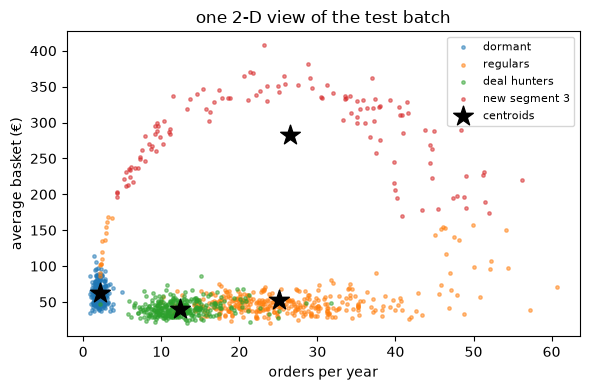

In [10]:
def curve_rows(n, r):
    th = r.uniform(0, np.pi, n)
    X = np.empty((n, 4))
    X[:, 1] = 60 + 300 * np.sin(th) * r.lognormal(0, 0.05, n)           # basket
    X[:, 0] = 2 + 48 * (1 - np.cos(th)) / 2 * r.lognormal(0, 0.10, n)   # orders
    X[:, 2] = np.clip(r.normal(0.05, 0.08, n), 0, 1)
    X[:, 3] = 30 * r.lognormal(0, 0.40, n)
    return X

def make_curve(w, r):
    X, g = make_batch(BATCH, BASE_SHARES, r)
    m = g == "big spenders"
    X[m] = curve_rows(m.sum(), r)
    return X, g

batches, latent = fresh_start()
log, alarms, _ = run_weeks(v1, 53, make_curve)
show_log(log)
d = decide(v1)
out_curve = kp.retrain_path(v1, batches, alarms[0].t_alarm_window_earliest, alarms[0].t_alarm, make_business_checks(make_curve), rng=rng)
report(out_curve)
cand = out_curve["candidate"]
print("hollow check per cluster (about 0.5–0.9 for a round cluster; 1.3 flags):")
show([(cand.names[c], n, r) for c, n, r in out_curve["hidden"]["hollow"]["clusters"]], ["cluster", "size", "5-NN distance at the centroid / typical"])
print("method review on the training window:")
rows, hdr = kp.method_review(cand.scaled(out_curve["backtest"]["X"]), cand.k, rng=rng)
show(rows, hdr)

X_test = out_curve["backtest"]["test"]
lab = cand.predict(X_test)
C = cand.centroids_raw()
fig, ax = plt.subplots(figsize=(6, 4))
for c in range(cand.k):
    ax.scatter(X_test[lab == c, 0], X_test[lab == c, 1], s=6, alpha=0.5, label=cand.names[c])
ax.scatter(C[:, 0], C[:, 1], marker="*", s=220, c="black", label="centroids")
ax.set_xlabel("orders per year"); ax.set_ylabel("average basket (€)"); ax.set_title("one 2-D view of the test batch")
ax.legend(fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

> **How to read this**
> * Signal 4 at 13% and signal 2 at 2.3: the curve's customers are far from any centroid. The scan keeps k = 4 and
>   step 5 would replace the centroids (shift 2.55, switch share 2.8%).
> * The fit checks stop it: the curve's cluster is hollow, 2.0 against 0.5–0.9 for the round ones. Its centroid
>   describes a customer with about 26 orders and a €200 basket who does not exist (the star in the plot).
> * The method review does not rescue it: all three methods find four groups, each stable, and they agree (ARI
>   0.86–0.95). Agreement is a consistency check, not a verdict. k-means can find the group; it cannot describe it
>   with a centroid. This segment needs a density method or a different representation (e.g. spend a year as a
>   feature, which turns the curve back into a blob).

<a id="s-kbudget"></a>

### 5.10 The business fixes k: 4 → 6 and 4 → 3

No alarm, a new requirement. For 4 → 6: fit at six, per-cluster stability, and the holdout decides whether the extra
segments pay. For 4 → 3: the refit merges by closeness in feature space, the merge plan merges by closeness in
outcomes, and each pair's cost in conversions says which to prefer. The response table is measured on a pilot, as
`holdout_experiment` does, not read off the simulator.

In [11]:
pool = np.vstack([X for _, X in HISTORY[-8:]])
gp = np.concatenate([LATENT[w] for w, _ in HISTORY[-8:]])
Z = v1.scaled(pool)
old = v1.predict(pool)

for kt in (6, 3):
    print("=" * 100 + f"\nk = {v1.k} -> {kt}")
    km, jac = kp.per_cluster_stability(Z, kt, rng=rng)
    Mct = kp.contingency(old, km.labels_)
    names = kp.names_from_contingency(Mct, v1.names)
    show([(names[c], int((km.labels_ == c).sum()), jac[c]) for c in range(kt)], ["cluster at k = %d" % kt, "size", "stability (mean Jaccard over 30 refits)"], "{:.2f}")
    show_contingency(Mct, v1.names, names)
    print("reading:", kp.classify_contingency(Mct))
    exp = holdout_experiment(gp, old, km.labels_, v1.names, names, KNOWN, rng)
    print(f"holdout: control {exp['control']:.1%} vs treatment {exp['treatment']:.1%}, lift {exp['lift']:+.1%} "
          f"(95% CI {exp['ci'][0]:+.1%} to {exp['ci'][1]:+.1%}), p = {exp['p_value']:.3f}; treatment campaigns {exp['policy_new']} (piloted: {exp['piloted']})")

print("=" * 100 + "\nmerge plan for 4 -> 3, from pilot-measured responses")
sizes = np.bincount(old, minlength=v1.k)
R = np.array([[respond(gp[old == s][c::len(CAMPAIGNS)], camp, rng).mean() for c, camp in enumerate(CAMPAIGNS)] for s in range(v1.k)])
show([(v1.names[s], int(sizes[s]), *R[s]) for s in range(v1.k)], ["segment", "size", *CAMPAIGNS])
pairs, hdr = kp.pair_merge_costs(sizes, R, [v1.names[s] for s in range(v1.k)])
show(pairs, hdr, "{:.1f}")
steps, hdr, final = kp.merge_plan(sizes, R, 3, [v1.names[s] for s in range(v1.k)])
print("the plan merges", steps[0][0], "with", steps[0][1], f"at {steps[0][2]:.1f} conversions per 1,000 customers; segments: {final}")

k = 4 -> 6


| cluster at k = 6 | size | stability (mean Jaccard over 30 refits) |
|---|---|---|
| regulars · a | 1018 | 0.94 |
| regulars · b | 1818 | 0.92 |
| deal hunters | 2395 | 1.00 |
| big spenders | 1217 | 0.90 |
| dormant · a | 503 | 0.92 |
| dormant · b | 1049 | 0.89 |

| old \ new | regulars · a | regulars · b | deal hunters | big spenders | dormant · a | dormant · b |
|---|---|---|---|---|---|---|
| regulars | 1018 | 1809 | 0 | 0 | 0 | 0 |
| deal hunters | 0 | 2 | 2395 | 0 | 0 | 1 |
| dormant | 0 | 0 | 0 | 0 | 503 | 1043 |
| big spenders | 0 | 7 | 0 | 1217 | 0 | 5 |

reading: clean split
holdout: control 13.2% vs treatment 12.6%, lift -0.5% (95% CI -2.2% to +1.2%), p = 0.554; treatment campaigns {'regulars · a': 'coupon', 'regulars · b': 'free_shipping', 'deal hunters': 'coupon', 'big spenders': 'premium_preview', 'dormant · a': 'winback', 'dormant · b': 'winback'} (piloted: ['regulars · a', 'regulars · b', 'dormant · a', 'dormant · b'])
k = 4 -> 3


| cluster at k = 3 | size | stability (mean Jaccard over 30 refits) |
|---|---|---|
| dormant | 2778 | 0.96 |
| regulars | 2824 | 0.92 |
| deal hunters | 2398 | 0.96 |

| old \ new | dormant | regulars | deal hunters |
|---|---|---|---|
| regulars | 4 | 2823 | 0 |
| deal hunters | 0 | 0 | 2398 |
| dormant | 1546 | 0 | 0 |
| big spenders | 1228 | 1 | 0 |

reading: clean merge
holdout: control 12.4% vs treatment 10.0%, lift -2.4% (95% CI -3.8% to -1.0%), p = 0.001; treatment campaigns {'dormant': 'winback', 'regulars': 'free_shipping', 'deal hunters': 'coupon'} (piloted: [])
merge plan for 4 -> 3, from pilot-measured responses


| segment | size | coupon | free_shipping | premium_preview | winback | app_push |
|---|---|---|---|---|---|---|
| regulars | 2827 | 0.083 | 0.092 | 0.042 | 0.009 | 0.011 |
| deal hunters | 2398 | 0.167 | 0.115 | 0.019 | 0.021 | 0.006 |
| dormant | 1546 | 0.023 | 0.016 | 0.006 | 0.078 | 0.013 |
| big spenders | 1229 | 0.024 | 0.016 | 0.098 | 0.008 | 0.012 |

| segment | merged with | cost: conversions lost per 1,000 customers |
|---|---|---|
| regulars | deal hunters | 3.1 |
| deal hunters | dormant | 10.6 |
| deal hunters | big spenders | 11.2 |
| regulars | dormant | 11.9 |
| regulars | big spenders | 12.5 |
| dormant | big spenders | 13.7 |

the plan merges regulars with deal hunters at 3.1 conversions per 1,000 customers; segments: ['regulars + deal hunters', 'dormant', 'big spenders']


> **How to read this**
> * 4 → 6: the two extra clusters split the regulars and the dormant along their long tails. The splits are stable
>   (Jaccard 0.89–0.94) but the holdout finds no lift (−0.5 pp, p = 0.55): the halves respond alike. Stable is
>   necessary, not sufficient. Deliver six if the business insists, flag the two splits, and let the outcomes per
>   segment decide at the next review.
> * 4 → 3: the refit merges the dormant with the big spenders, the two closest in feature space (both order rarely).
>   The holdout prices that merge at −2.4 pp (p = 0.001). The merge plan, from measured responses, merges regulars
>   with deal hunters at 3.1 conversions per 1,000 customers; the refit's merge costs 13.7. Merge by outcome
>   similarity, not by centroid closeness.

<a id="s-concept"></a>

### 5.11 Concept drift: no signal moves, the business metric does; a new feature, then re-cluster

The case part 1 could only describe. Half of the deal hunters stop chasing coupons and start chasing free shipping.
Their features don't change, so signals 1–4 stay flat for eight weeks while coupon redemption in the deal-hunters
segment falls from about 18% to about 11%. The fix is a new feature (shipping sensitivity), which is the "upstream
feature change" trigger: the training window can only start when the feature exists, so the retrain waits for
eight weeks of it, then the k-scan, real?, the contingency table, the holdout, and the names.

In [12]:
define_group("deal hunters: shipping", GROUPS["deal hunters"][0], [0.04, 0.20, 0.02, 0.02, 0.01])
SHARES_CD = {**{g: s for g, s in BASE_SHARES.items() if g != "deal hunters"}, "deal hunters": 0.15, "deal hunters: shipping": 0.15}
make_cd = lambda w, r: make_batch(BATCH, SHARES_CD, r)
dh = next(c for c, n in v1.names.items() if n == "deal hunters")

batches, latent = fresh_start()
before = np.mean([respond(LATENT[w][v1.predict(X) == dh], "coupon", rng).mean() for w, X in HISTORY[-8:]])
log, alarms, _ = run_weeks(v1, 53, make_cd, weeks=8, stop_on_alarm=False)
rows = [(*row, f"{respond(latent[w][v1.predict(X) == dh], 'coupon', rng).mean():.1%}") for (w, X), row in zip(batches[-8:], log)]
show(rows, ["week", "signal 1: largest D (feature)", "signal 1 per segment", "signal 2", "signal 3", "signal 4", "outside the band", "alarm",
            "coupon redemption, deal hunters"])
print(f"alarms: {[a.key for a in alarms] or 'none'}; coupon redemption in the deal hunters before the change: {before:.1%}")

# the new feature exists from week 61; only data under the new definition can train
MED5 = {g: [*GROUPS[g][0], 0.3] for g in SHARES_CD}
MED5["deal hunters"][4], MED5["deal hunters: shipping"][4] = 0.2, 0.8
make_cd5 = lambda w, r: make_batch(BATCH, SHARES_CD, r, medians=MED5)
FEATURES5 = FEATURES + ["shipping_sensitivity"]
new = []
for w in range(61, 69):
    X, g = make_cd5(w, rng); new.append((w, X)); latent[w] = g
Xw = np.vstack([X for _, X in new])
scaler5 = StandardScaler().fit(Xw)
scan = kp.k_scan(scaler5.transform(Xw), rng=rng)
print(f"k-scan on weeks 61–68 with the new feature: {scan['picks']} -> k = {scan['k']}")
show(scan["table"], scan["headers"])
v3 = kp.fit_model_version(Xw, scan["k"], FEATURES5, BATCH, version=2, train_window=(61, 68), previous=v1, rng=rng)
pool = np.vstack([X for _, X in new[-4:]])
lo, ln = v1.predict(pool[:, :4]), v3.predict(pool)
Mct = kp.contingency(lo, ln)
v3.names = kp.names_from_contingency(Mct, v1.names)      # the feature space changed: names by membership, not by centroid
show_contingency(Mct, v1.names, v3.names)
print("reading:", kp.classify_contingency(Mct))
r = kp.new_k_is_real(scaler5.transform(Xw), v1.k, v3.k, time_slices=[scaler5.transform(X) for _, X in new[-4:]], rng=rng)
print(f"real? wins {r['wins']:.0%}, gain {r['gain_median']:+.3f} ({r['gain_p5']:+.3f} to {r['gain_p95']:+.3f}), time windows {r['time_window_wins']:.0%} -> {r['real']}")
test = [make_cd5(w, rng) for w in range(69, 77)]
Xt, gt = np.vstack([X for X, _ in test]), np.concatenate([g for _, g in test])
exp = holdout_experiment(gt, v1.predict(Xt[:, :4]), v3.predict(Xt), v1.names, v3.names, KNOWN, rng)
print(f"meaningful? holdout on weeks 69–76: control {exp['control']:.1%} vs treatment {exp['treatment']:.1%}, lift {exp['lift']:+.1%} "
      f"(95% CI {exp['ci'][0]:+.1%} to {exp['ci'][1]:+.1%}), p = {exp['p_value']:.3f}; treatment campaigns {exp['policy_new']} (piloted: {exp['piloted']})")
display(Markdown(kp.format_profiles(kp.profile_clusters(pool, ln, FEATURES5, v3.scaled(pool), rng=rng), v3.names)))

| week | signal 1: largest D (feature) | signal 1 per segment | signal 2 | signal 3 | signal 4 | outside the band | alarm | coupon redemption, deal hunters |
|---|---|---|---|---|---|---|---|---|
| 53 | days_since_last_order 0.035 | 0.117 | 0.709 | 0.002 | 0.8% | — |  | 10.4% |
| 54 | orders_per_year 0.060 | 0.089 | 0.736 | 0.009 | 1.0% | s1:orders_per_year above |  | 11.3% |
| 55 | discount_share 0.033 | 0.129 | 0.711 | 0.001 | 0.8% | — |  | 11.7% |
| 56 | orders_per_year 0.043 | 0.148 | 0.687 | 0.002 | 0.7% | — |  | 8.2% |
| 57 | orders_per_year 0.038 | 0.079 | 0.726 | 0.004 | 0.9% | — |  | 7.7% |
| 58 | discount_share 0.038 | 0.092 | 0.655 | 0.003 | 0.4% | — |  | 11.0% |
| 59 | orders_per_year 0.039 | 0.096 | 0.713 | 0.003 | 0.9% | — |  | 12.1% |
| 60 | discount_share 0.032 | 0.098 | 0.667 | 0.002 | 0.8% | — |  | 10.8% |

alarms: none; coupon redemption in the deal hunters before the change: 17.6%


k-scan on weeks 61–68 with the new feature: {'elbow': 5, 'silhouette': 5, 'gap': 8} -> k = 5


| k | inertia | silhouette | stability (ARI) | gap |
|---|---|---|---|---|
| 2 | 14047.770 | 0.345 | 0.705 | 1.263 |
| 3 | 9792.019 | 0.406 | 0.942 | 1.418 |
| 4 | 6303.938 | 0.505 | 0.977 | 1.706 |
| 5 | 4045.615 | 0.560 | 1.000 | 2.053 |
| 6 | 3518.264 | 0.522 | 0.948 | 2.103 |
| 7 | 3044.340 | 0.439 | 0.959 | 2.178 |
| 8 | 2764.337 | 0.406 | 0.915 | 2.205 |

| old \ new | deal hunters · a | regulars | dormant | big spenders | deal hunters · b |
|---|---|---|---|---|---|
| regulars | 1 | 1417 | 0 | 0 | 0 |
| deal hunters | 573 | 2 | 0 | 0 | 644 |
| dormant | 1 | 0 | 811 | 0 | 0 |
| big spenders | 0 | 0 | 0 | 551 | 0 |

reading: clean split


real? wins 100%, gain +0.051 (+0.046 to +0.065), time windows 100% -> True
meaningful? holdout on weeks 69–76: control 9.1% vs treatment 11.2%, lift +2.1% (95% CI +0.7% to +3.5%), p = 0.004; treatment campaigns {'deal hunters · a': 'free_shipping', 'regulars': 'free_shipping', 'dormant': 'winback', 'big spenders': 'premium_preview', 'deal hunters · b': 'coupon'} (piloted: ['deal hunters · a', 'deal hunters · b'])


| cluster | size | silhouette | distinguishing features (median, difference from average) |
|---|---|---|---|
| deal hunters · a | 575 (14%) | 0.63 | shipping_sensitivity 0.803 (+2.0 sd), discount_share 0.597 (+1.4 sd), avg_basket_eur 40.8 (-0.5 sd) |
| regulars | 1,419 (35%) | 0.52 | orders_per_year 24 (+1.1 sd), discount_share 0.0992 (-0.7 sd), days_since_last_order 12 (-0.5 sd) |
| dormant | 811 (20%) | 0.51 | days_since_last_order 200 (+1.7 sd), orders_per_year 2.04 (-1.2 sd), discount_share 0.148 (-0.4 sd) |
| big spenders | 551 (14%) | 0.56 | avg_basket_eur 176 (+2.3 sd), discount_share 0.0532 (-0.8 sd), orders_per_year 7.92 (-0.6 sd) |
| deal hunters · b | 644 (16%) | 0.58 | discount_share 0.599 (+1.4 sd), shipping_sensitivity 0.199 (-0.7 sd), avg_basket_eur 40.2 (-0.5 sd) |

> **How to read this**
> * Eight weeks, one lone breach, no alarm: the deal hunters' four features have not moved. Coupon redemption in that
>   segment fell from 17.6% to 8–12%; only the business metric saw it.
> * With shipping sensitivity added, the scan says 5 and the contingency table shows a clean split of the deal
>   hunters (573 / 644); the other three segments are untouched. Real: 100% of subsamples.
> * The holdout: the two halves were piloted; one keeps coupons, the other gets free shipping. Lift +2.1 pp (CI +0.7
>   to +3.5, p = 0.004): adopt. The cards name them: "deal hunters · a" has shipping sensitivity 0.80, "· b" 0.20.

<a id="s-summary"></a>

### 5.12 What the eleven runs showed

| scenario | what fired | decided by | outcome |
|---|---|---|---|
| 5.2 healthy weeks | nothing | — | no alarm in 8 weeks |
| 5.3 a new group | all four signals; signal 4 at 9% | step 4, real + meaningful | adopt k = 5; the new cluster named from its card |
| 5.4 the group leaves | signal 3 under v2 | the rollback check | roll back to v1 |
| 5.5 mix shift | signal 3 (and global signal 1) | the trigger table | keep, report, rebaseline |
| 5.6 broken inputs | signals 2 and 4 below; signal 1 names the column | `data_checks` | fix the data; a retrain would have merged two segments |
| 5.7 a segment splits | signal 2; per-segment signal 1 at 2× its edge names the segment | step 4, real but not meaningful | keep k = 4, track sub-segments |
| 5.8 a segment drifts | per-segment signal 1, then 2 and 4 | step 5 | replace silently / replace visibly / keep |
| 5.9 a segment becomes a curve | signals 2 and 4 | step 3's fit checks | k-means no longer fits this segment: method review |
| 5.10 the business fixes k | nothing | per-cluster stability, holdout, merge costs | 6: stable but no lift; 3: merge by outcome, not by distance |
| 5.11 concept drift | nothing; the business metric | the k-scan after a new feature, real + meaningful | adopt k = 5 |

Two things the runs taught the write-up: signals 2 and 4 have to be reweighted to the training shares, or a mix
shift moves them; and a hollow cluster (the centroid in empty space) is the fit check that catches a curve, since
the k-scan, the same-k decision and the method review all pass it.